# CA3: Data Visualisations
**Student:** Roksolana Kryvulia

**Dataset CA1:** Wine Quality (UCI id=186)

**Dataset CA2:** population.csv

**Libraries used:** Matplotlib, Seaborn, Bokeh, hvplot, Plotly

In [1]:
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns

from bokeh.plotting import figure, show, output_notebook
from bokeh.models import HoverTool, ColumnDataSource, RangeSlider, Spinner, CustomJS, Range1d, DatetimeTickFormatter
from bokeh.layouts import layout, column
from bokeh.embed import file_html
from bokeh.resources import CDN


import hvplot.pandas  
import holoviews as hv

import plotly.express as px
import plotly.graph_objects as go

from sklearn.metrics import roc_curve, auc, confusion_matrix, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

from IPython.display import HTML, display

output_notebook()
hv.extension('bokeh')


sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

Loading BokehJS ...

'pip' is not recognized as an internal or external command,
operable program or batch file.


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


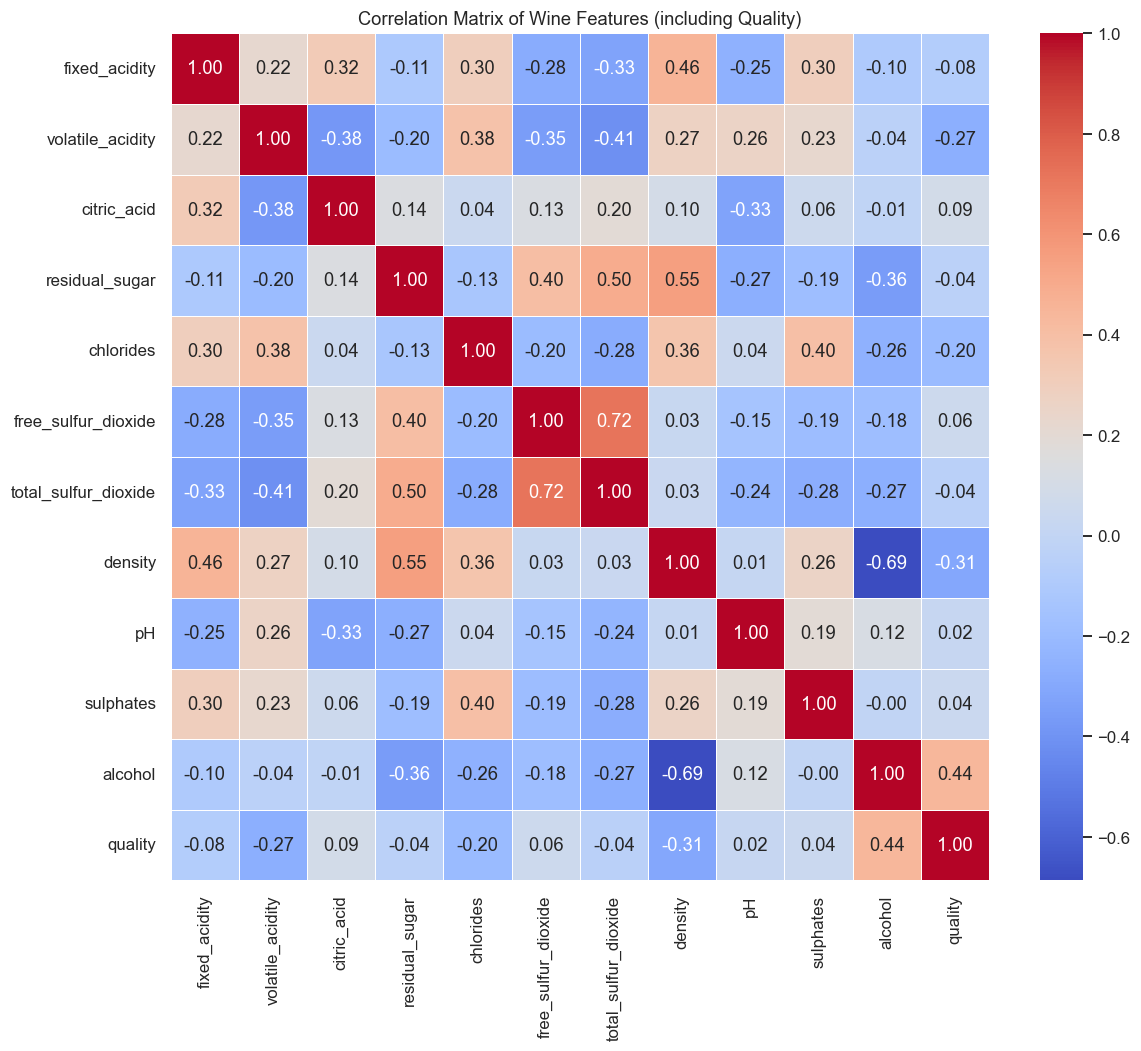

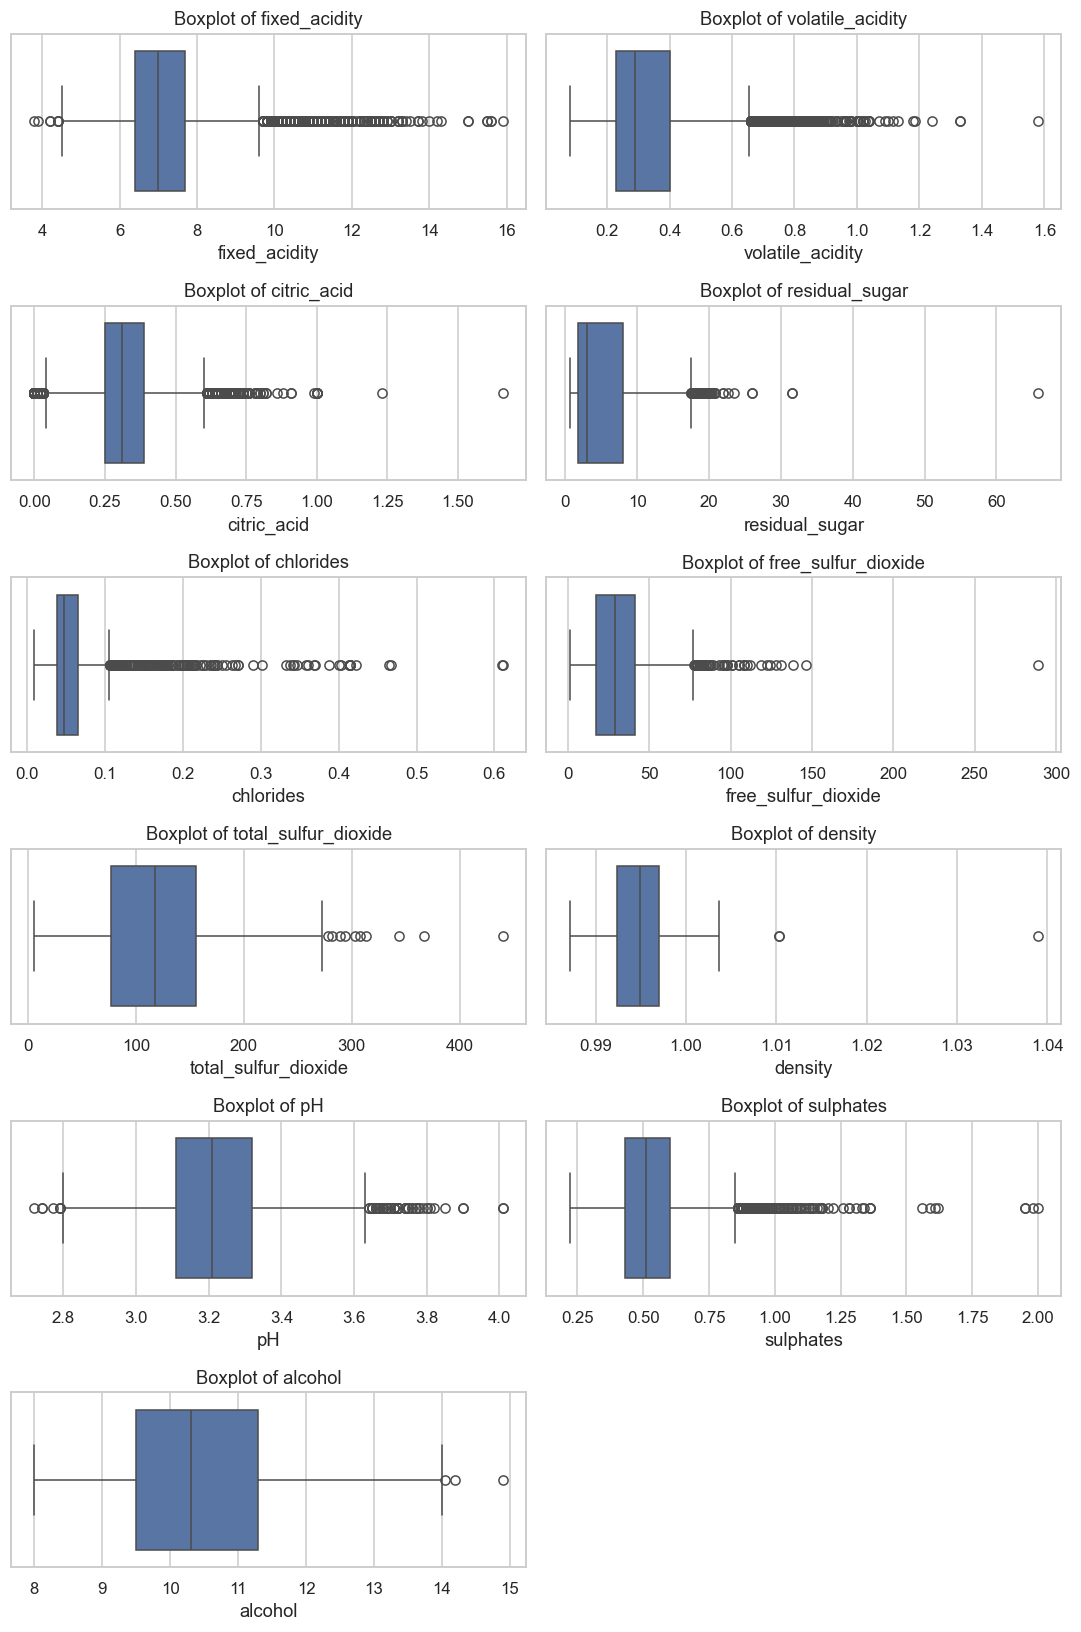

Rows remaining after cleaning: 5093


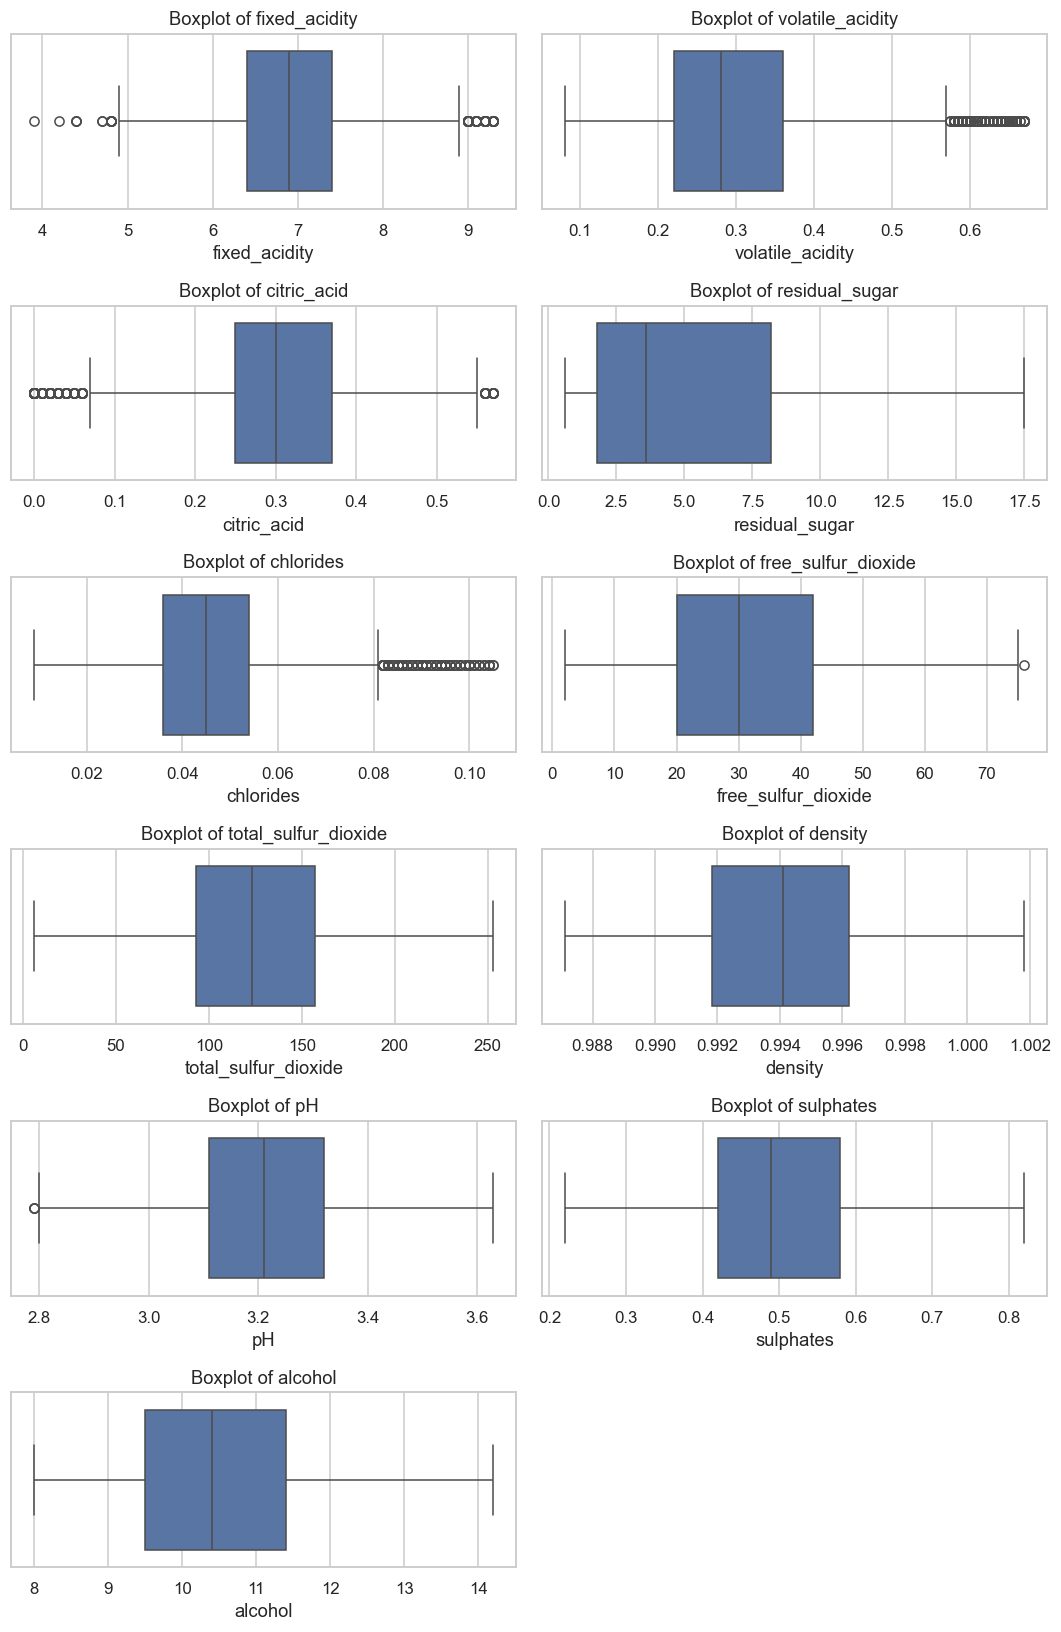

high_quality
0    4002
1    1091
Name: count, dtype: int64
high_quality
0    78.578441
1    21.421559
Name: proportion, dtype: float64
Training set: (4074, 11)
Test set: (1019, 11)
R² Score : 0.2024
MAE      : 0.6027
MSE      : 0.5724
RMSE     : 0.7566
Statsmodels: Linear Regression Model 1 - Alcohol
                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.189
Model:                            OLS   Adj. R-squared:                  0.189
Method:                 Least Squares   F-statistic:                     948.2
Date:                Thu, 30 Apr 2026   Prob (F-statistic):          2.24e-187
Time:                        18:25:38   Log-Likelihood:                -4786.0
No. Observations:                4074   AIC:                             9576.
Df Residuals:                    4072   BIC:                             9589.
Df Model:                           1                             

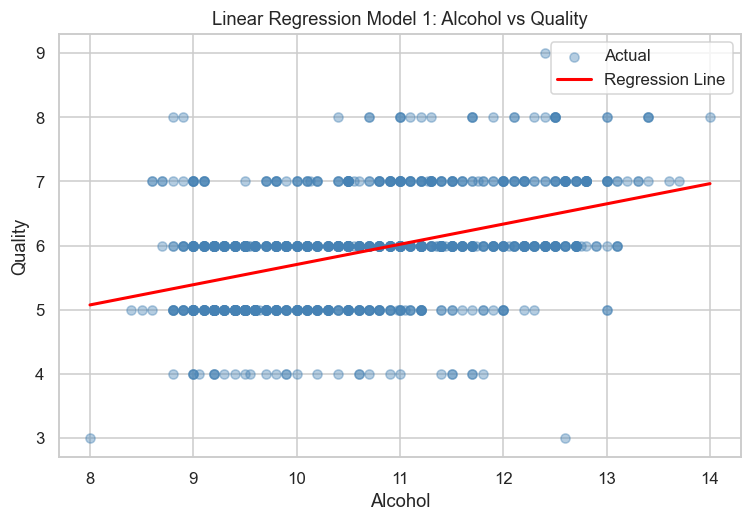

Scikit-learn: Linear Regression Model 2 - Density ===
R² Score : 0.1144
MAE      : 0.6252
MSE      : 0.6356
RMSE     : 0.7972
Statsmodels: Linear Regression Model 2 - Density
                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     412.3
Date:                Thu, 30 Apr 2026   Prob (F-statistic):           2.12e-87
Time:                        18:25:38   Log-Likelihood:                -5016.0
No. Observations:                4074   AIC:                         1.004e+04
Df Residuals:                    4072   BIC:                         1.005e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err   

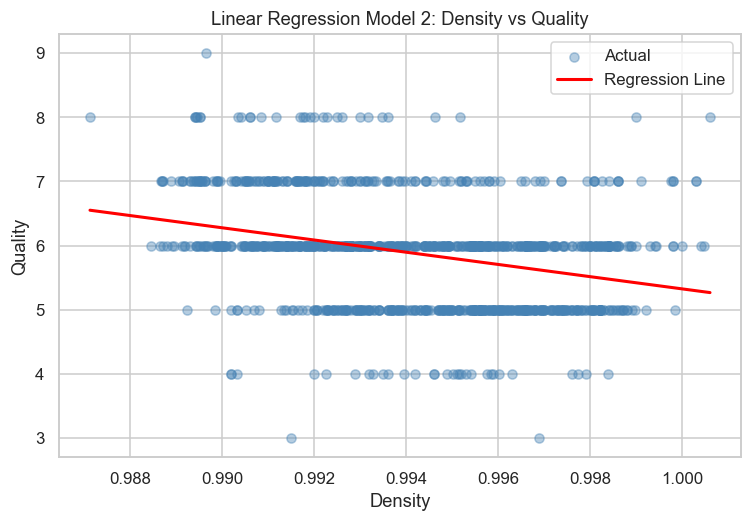

Scikit-learn: Multiple Regression Model 1 - All Features
R² Score : 0.2751
MAE      : 0.5589
MSE      : 0.5202
RMSE     : 0.7213
Statsmodels: Multiple Regression Model 1 - All Features
                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.276
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     140.9
Date:                Thu, 30 Apr 2026   Prob (F-statistic):          3.78e-275
Time:                        18:25:38   Log-Likelihood:                -4554.1
No. Observations:                4074   AIC:                             9132.
Df Residuals:                    4062   BIC:                             9208.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    

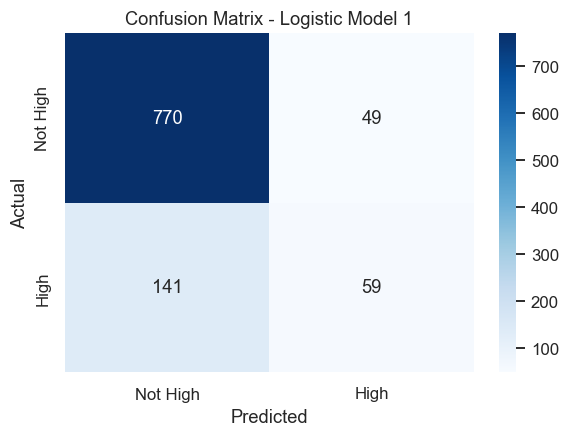

Logistic Regression Model 2
Accuracy: 0.8077

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89       819
           1       0.52      0.23      0.32       200

    accuracy                           0.81      1019
   macro avg       0.68      0.59      0.61      1019
weighted avg       0.77      0.81      0.78      1019



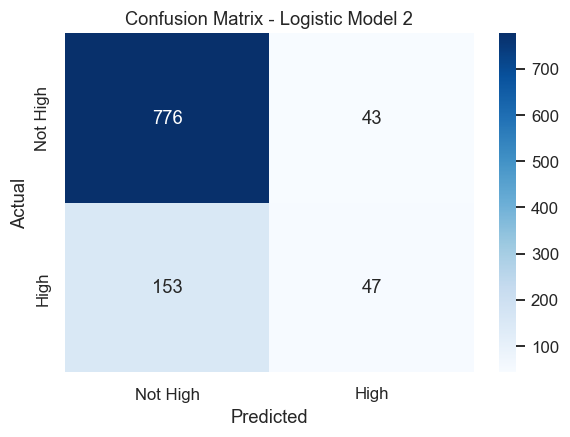

Shape: (816, 1)
Missing values in value: 0
Duplicate index labels: 0
               value
date                
1952-01-01  156309.0
1952-02-01  156527.0
1952-03-01  156731.0 
                  value
date                  
2019-10-01  329982.035
2019-11-01  330154.949
2019-12-01  330309.946
count       8.160000e+02
mean        2.438478e+05
median      2.395575e+05
std         5.051914e+04
variance    2.552184e+09
min         1.563090e+05
max         3.303099e+05
skewness    7.572817e-02
kurtosis   -1.191617e+00
Q25         2.017252e+05
Q75         2.893642e+05

Mode of calendar month index: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Mode of raw value (often uninformative for continuous counts): [156309.0, 156527.0, 156731.0]


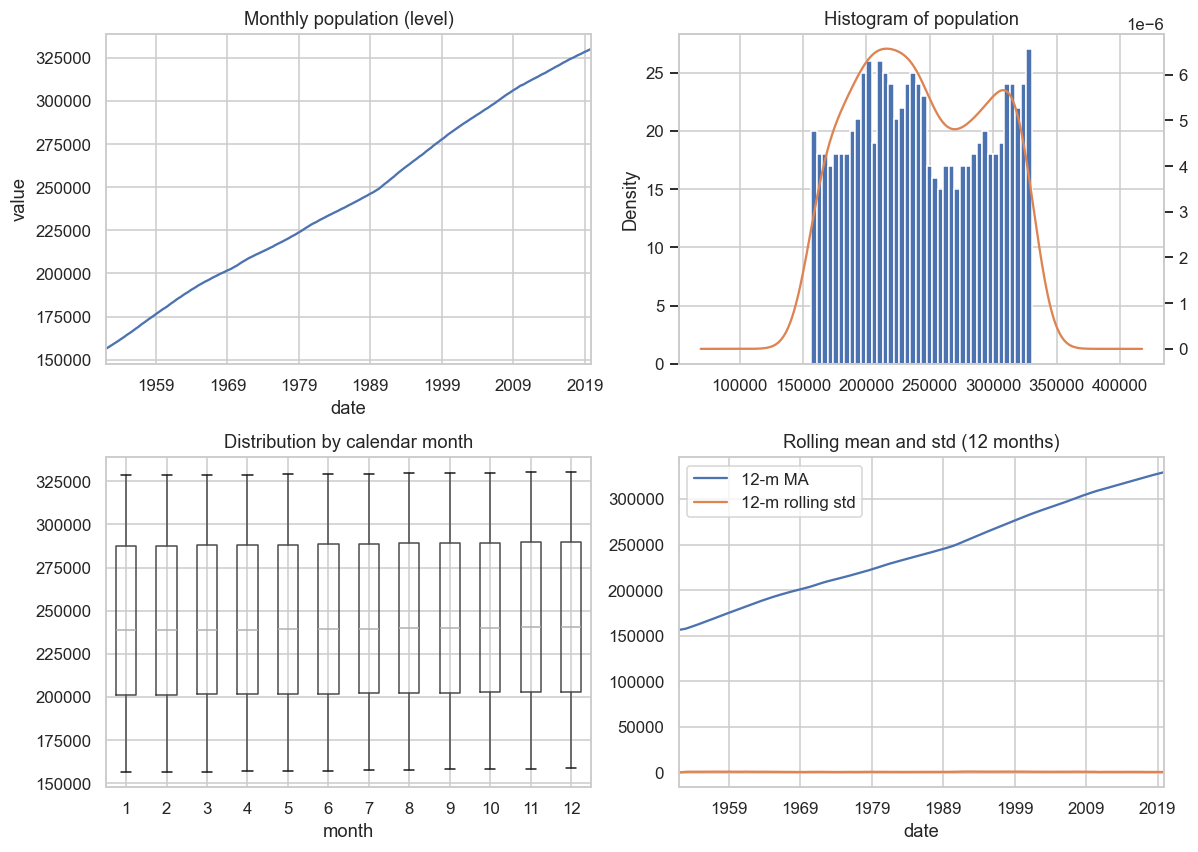

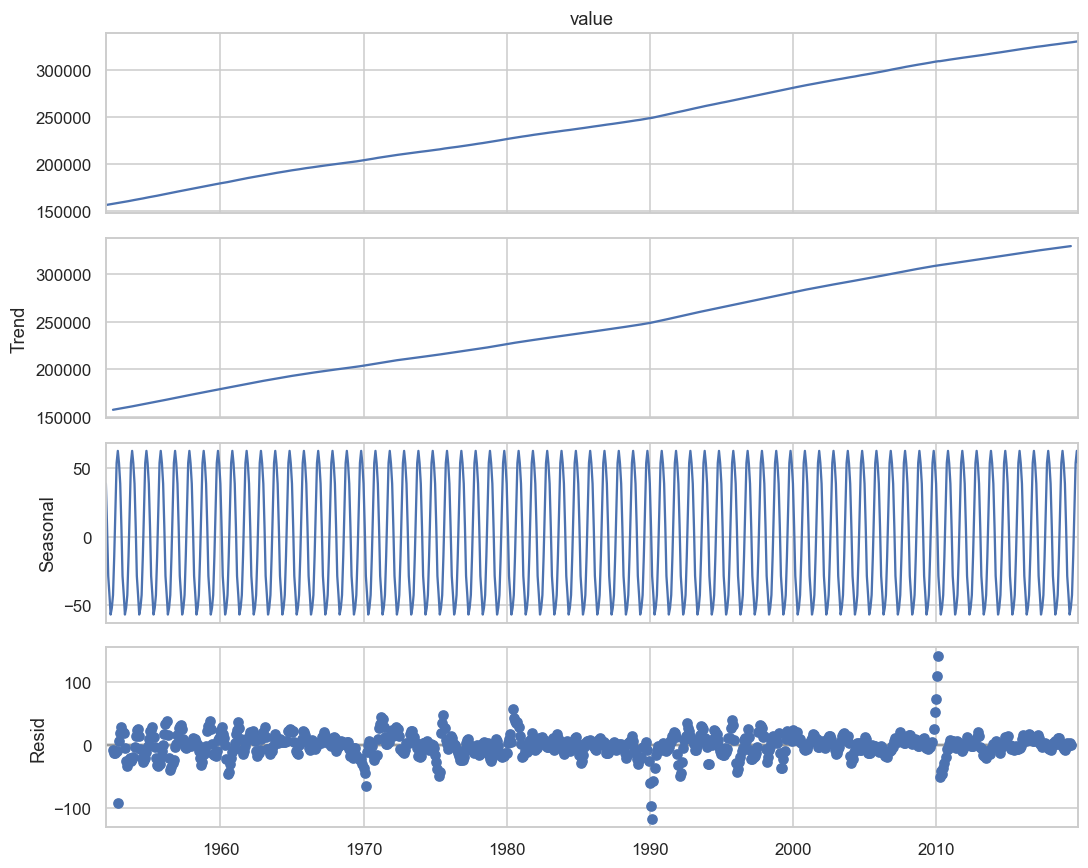

Mean absolute seasonal component: 39.488 (vs level mean 243847.8)
Level: ADF=-0.6653, p-value=0.8555, lags=17 -> Non-stationary (fail to reject H0)
First difference: ADF=-2.0099, p-value=0.2823, lags=21 -> Non-stationary (fail to reject H0)
Lag-12 (seasonal) difference: ADF=-2.4067, p-value=0.1399, lags=17 -> Non-stationary (fail to reject H0)
Seasonal diff + first diff: ADF=-5.5611, p-value=1.541e-06, lags=14 -> Stationary (reject H0 at 5%)
Level (constant+trend) KPSS: stat=0.7377, p-value=0.01, lags=18 -> Reject H0 (evidence of non-stationarity)


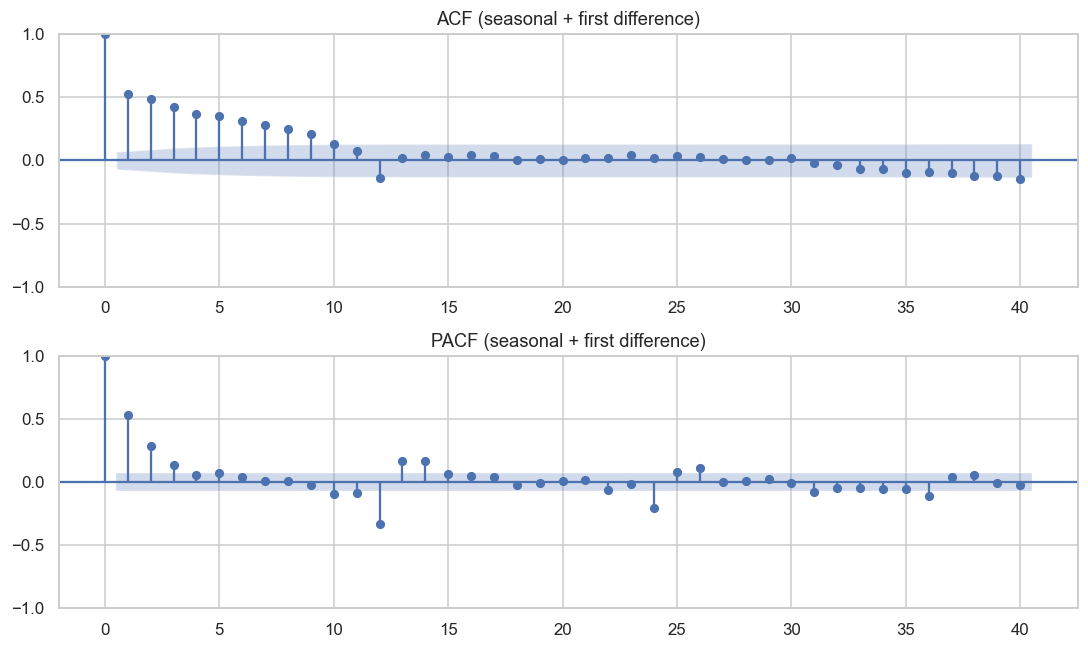

Train: 1952-01-01 .. 2016-12-01 (n=780)
Test:  2017-01-01 .. 2019-12-01 (n=36)
Chosen ARIMA order (p,d,q): (3, 1, 1) AIC: 7052.239387818892


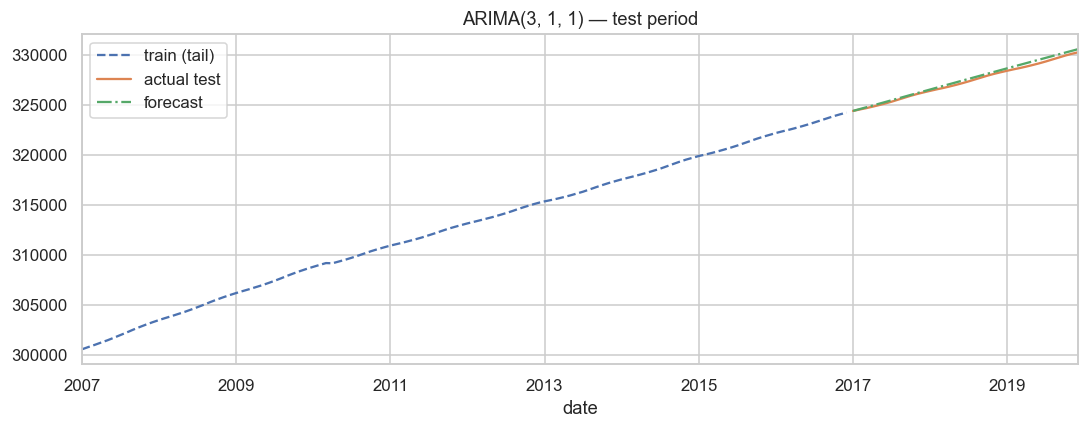

Chosen SARIMAX order: (1, 1, 1) seasonal: (0, 1, 1, 12) AIC: 6192.529372210979


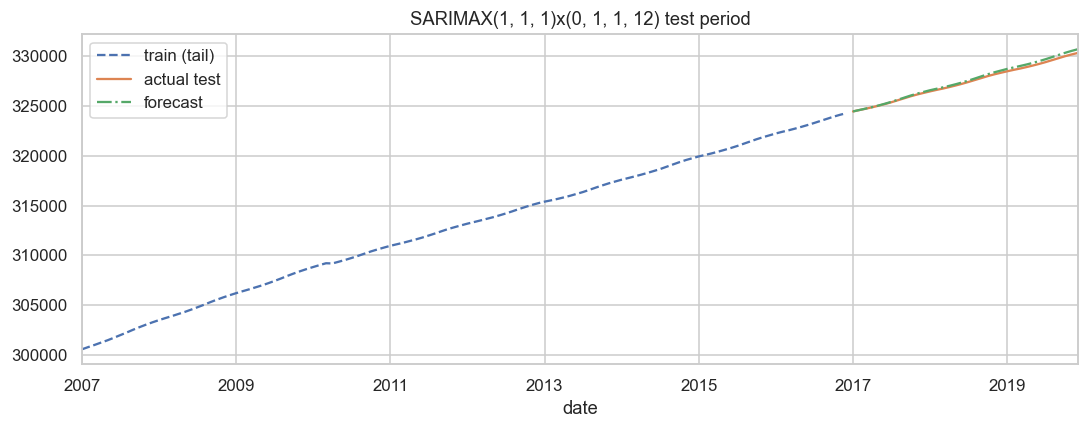

Holt–Winters (train) AIC: 5667.329848664173 BIC: 5741.878551379112


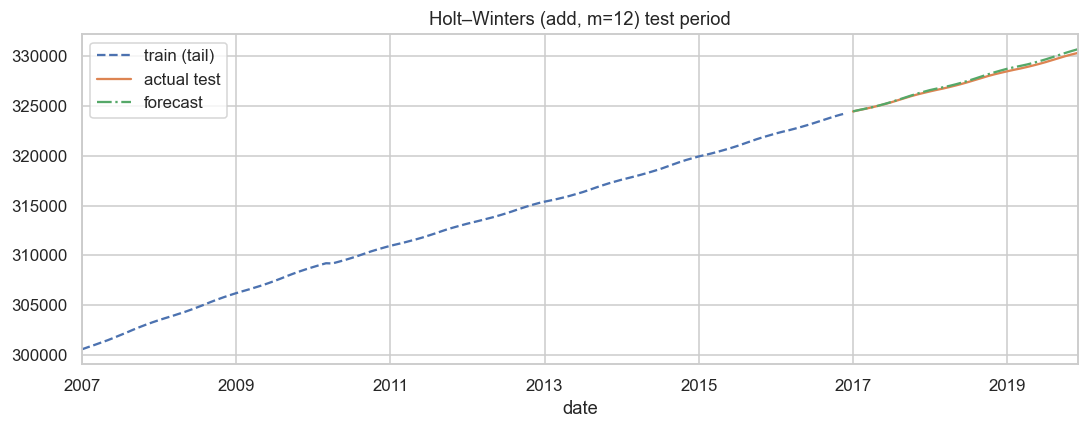

=== Test set accuracy ===
                        model       RMSE        MAE   MAPE_%
               ARIMA(3, 1, 1) 232.125195 210.401044 0.064133
SARIMAX(1, 1, 1)(0, 1, 1, 12) 195.958753 162.596714 0.049496
          HoltWinters_add_m12 190.858521 157.496115 0.047942

=== train ===
                        model         AIC         BIC
               ARIMA(3, 1, 1) 7052.239388 7075.529443
SARIMAX(1, 1, 1)(0, 1, 1, 12) 6192.529372 6211.025633
          HoltWinters_add_m12 5667.329849 5741.878551

Best model by RMSE: HoltWinters_add_m12 (RMSE=190.86, MAE=157.50, MAPE=0.05%)
ARIMA: Ljung-Box p-value (lag 12) = 1


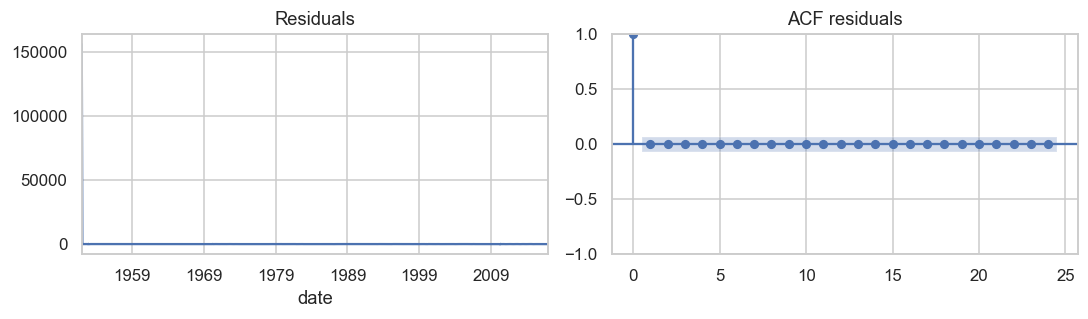

SARIMAX: Ljung-Box p-value (lag 12) = 3.795e-47


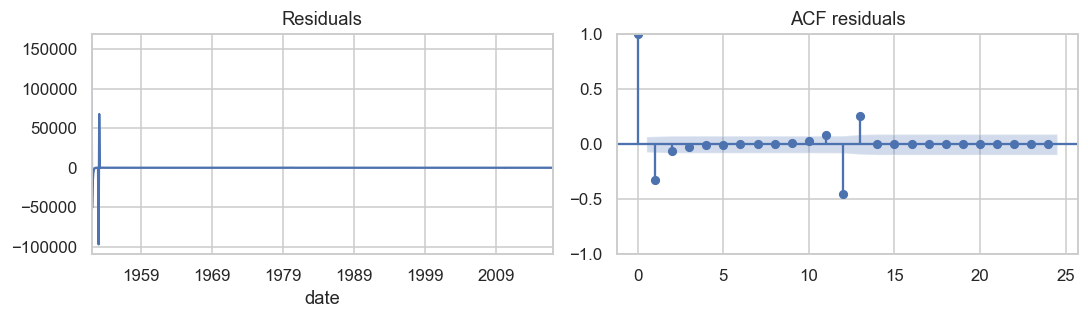

HoltWinters: Ljung-Box p-value (lag 12) = 3.561e-21


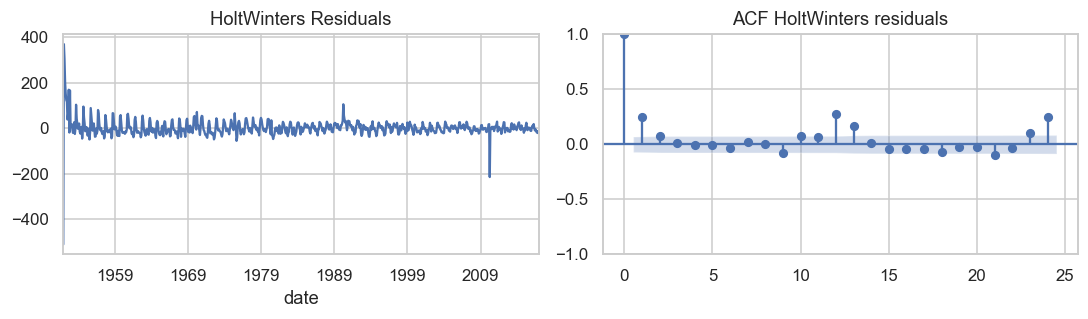

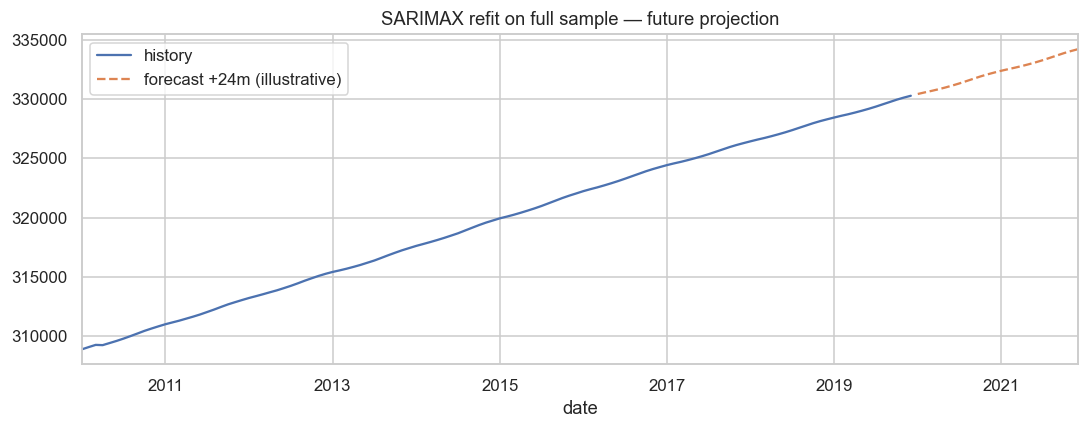

2020-01-01    330460.850967
2020-02-01    330595.611151
2020-03-01    330725.782294
2020-04-01    330865.102424
2020-05-01    331017.599811
2020-06-01    331183.088984
Freq: MS
...
2021-07-01    333335.131039
2021-08-01    333530.276975
2021-09-01    333727.783968
2021-10-01    333923.567555
2021-11-01    334098.566314
2021-12-01    334255.903192
Freq: MS


In [ ]:
# Run CA1 and CA2 inline
%run ca1_fixed.ipynb
%run ca2_fixed.ipynb

## Section 1: Data Analysis and Cleaning

### 1a. Correlation heatmap (Seaborn)

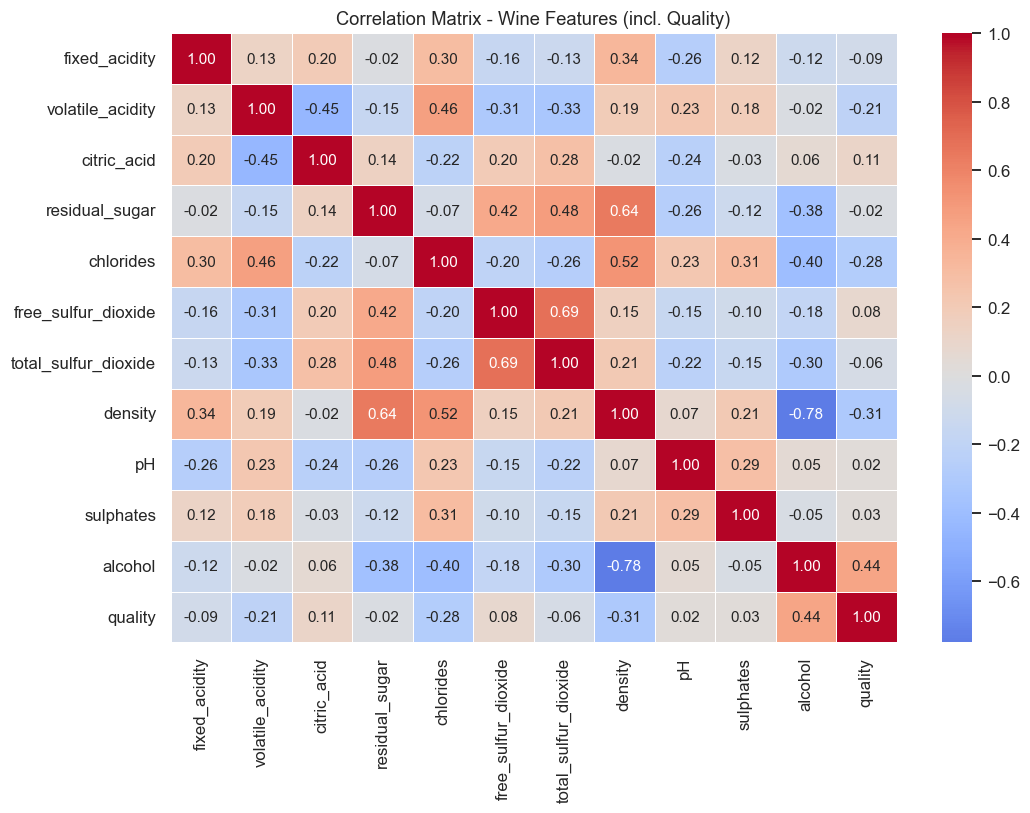


Correlation with quality (sorted):
alcohol                 0.438
density                -0.311
chlorides              -0.276
volatile_acidity       -0.215
citric_acid             0.112
fixed_acidity          -0.089
free_sulfur_dioxide     0.079
total_sulfur_dioxide   -0.057
sulphates               0.027
residual_sugar         -0.023
pH                      0.021
Name: quality, dtype: float64


In [ ]:
corr = df.drop(columns=['high_quality']).corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.4, ax=ax)
ax.set_title('Correlation Matrix - Wine Features (incl. Quality)')
plt.tight_layout()
plt.show()


print('\nCorrelation with quality (sorted):')
print(corr['quality'].drop('quality').sort_values(key=abs, ascending=False).round(3))

The bottom row / right column of the heatmap shows each predictor's correlation with `quality`. The printed sort confirms `alcohol` has the strongest positive link with quality (r = +0.438). `density` is the strongest negative driver (r = -0.311), followed by `chlorides` (r = -0.276) and `volatile_acidity` (r = -0.215). These four drivers are the features picked for Linear Regression Models 1 and 2 (alcohol, density) and Multiple Regression Model 2 (alcohol, volatile_acidity, density) in CA1.

**Why I used this library:** I used Seaborn because `heatmap` labels every cell with one keyword (`annot=True`) and gives a colour scale around zero. In raw Matplotlib, I would need `imshow` and loops to write each text label.

### 1b. Distribution of `residual_sugar` before vs after IQR cleaning (Seaborn)

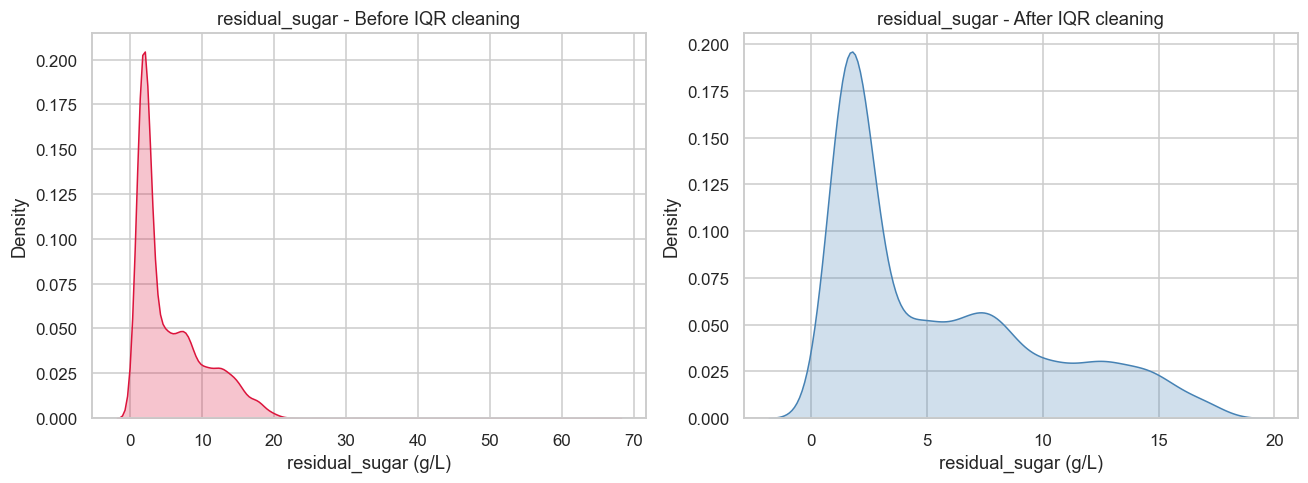

Rows before cleaning: 6497 | Rows after cleaning: 5093
Max residual_sugar before: 65.80 | after: 17.50


In [30]:
raw_rs = wine_quality.data.features['residual_sugar'].dropna()
clean_rs = df['residual_sugar']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, data, color, label in [
    (axes[0], raw_rs, 'crimson', 'Before IQR cleaning'),
    (axes[1], clean_rs, 'steelblue', 'After IQR cleaning'),
]:
    sns.kdeplot(data, fill=True, ax=ax, color=color)
    ax.set_title(f'residual_sugar - {label}')
    ax.set_xlabel('residual_sugar (g/L)')
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

print(f'Rows before cleaning: {len(raw_rs)} | Rows after cleaning: {len(clean_rs)}')
print(f'Max residual_sugar before: {raw_rs.max():.2f} | after: {clean_rs.max():.2f}')

The raw `residual_sugar` values have a long right tail (max = 65.80 g/L). This pulls up the mean and variance. After IQR cleaning, the maximum drops to 17.50 g/L and the data stays around the main sweetness range. The dataset goes from 6,497 rows to 5,093 rows (-21.6 %). The removed rows are the long-tail outliers shown in red.

**Why I used this library:** I chose Seaborn because `sns.kdeplot(..., fill=True)` makes a filled KDE curve in one call, with good default settings.

### 1c. Boxplots before vs after cleaning (Seaborn)

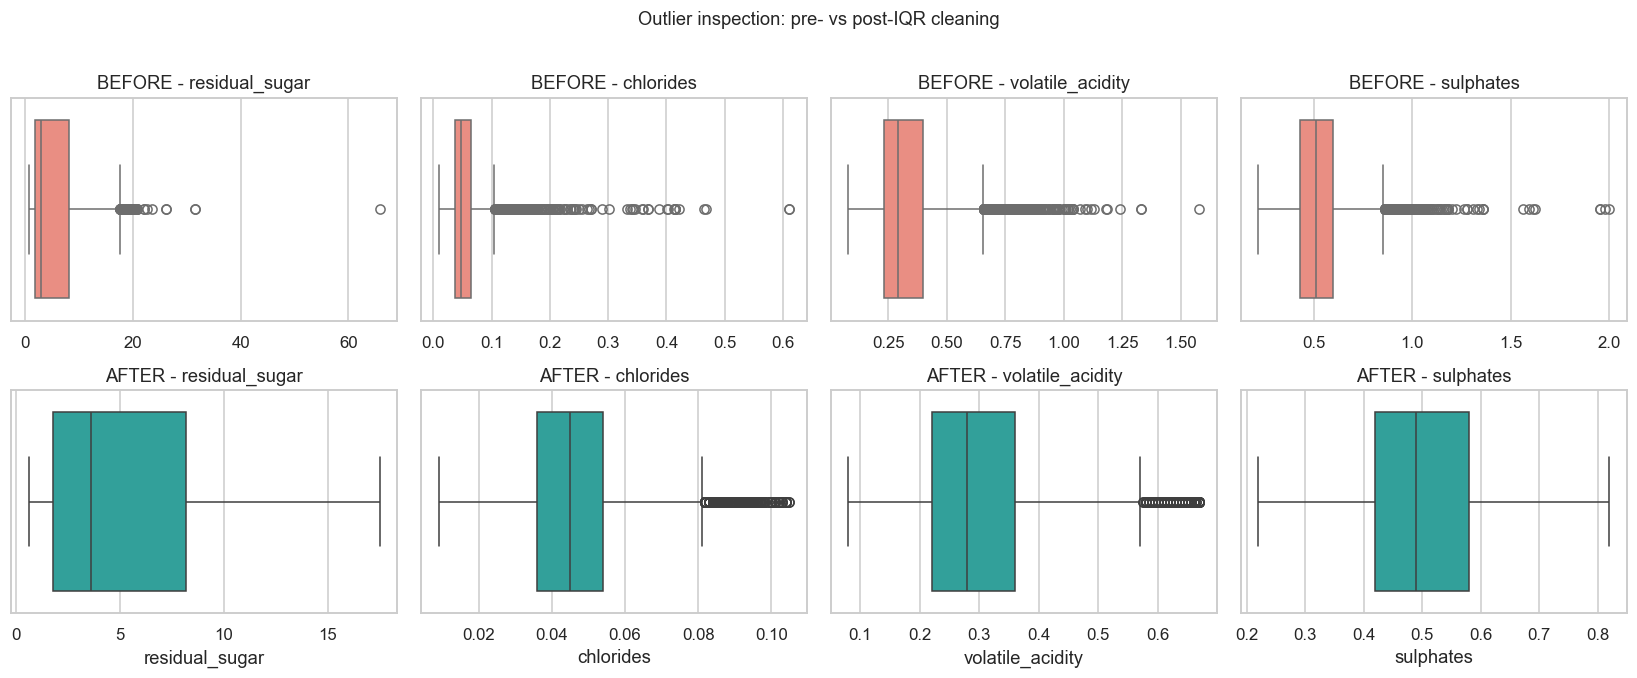

In [31]:
key_features = ['residual_sugar', 'chlorides', 'volatile_acidity', 'sulphates']
raw = wine_quality.data.features

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, feat in enumerate(key_features):
    sns.boxplot(x=raw[feat], ax=axes[0, i], color='salmon')
    axes[0, i].set_title(f'BEFORE - {feat}')
    axes[0, i].set_xlabel('')
    sns.boxplot(x=df[feat], ax=axes[1, i], color='lightseagreen')
    axes[1, i].set_title(f'AFTER - {feat}')
    axes[1, i].set_xlabel(feat)

fig.suptitle('Outlier inspection: pre- vs post-IQR cleaning', y=1.02)
plt.tight_layout()
plt.show()

The top row has long upper whiskers and many high outliers. The bottom row shows the same features. The whiskers shrink a lot. For `residual_sugar`, the upper whisker drops from 65.80 to 17.50, a 73 % drop. Only a few borderline points remain. The colours make the before and after comparison clear.

**Why I used this library:** I used boxplots because they are clear for outlier checks. I chose Seaborn because `boxplot` gives me a styled chart in one line. In plain Matplotlib, I would need to calculate quartiles and draw the whiskers and boxes myself.

### 1d. Class imbalance bar chart (Matplotlib)

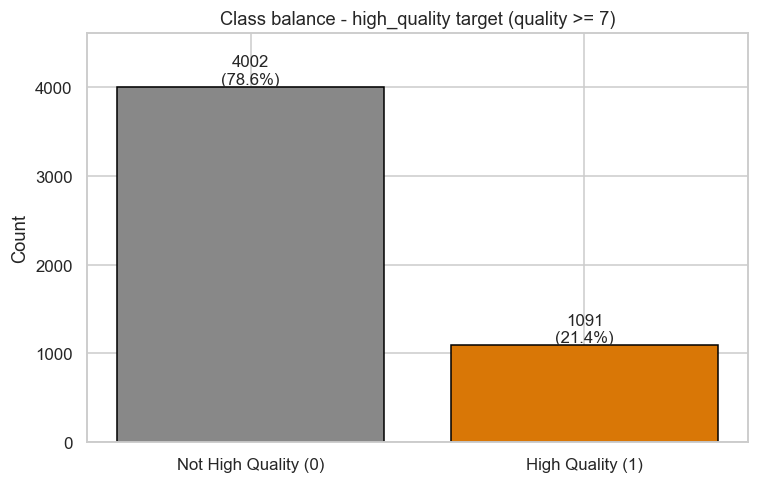

In [32]:
counts = df['high_quality'].value_counts().sort_index()
labels = ['Not High Quality (0)', 'High Quality (1)']
colors = ['#888888', '#d97706']  # grey for bigger class, amber for smaller class

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, counts.values, color=colors, edgecolor='black')

total = counts.sum()
for bar, val in zip(bars, counts.values):
    pct = val / total * 100
    ax.text(bar.get_x() + bar.get_width() / 2, val,
            f'{val}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11)

ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel('Count')
ax.set_title('Class balance - high_quality target (quality >= 7)')
plt.tight_layout()
plt.show()

**What this shows:** The binary target is imbalanced 4,002 'Not High Quality' samples (78.6 %) versus only 1,091 'High Quality' samples (21.4 %).

**Library:** I chosed Plain Matplotlib here because a two bar chart with annotated percentages does not need an extra dependency. 


## Linear

### 2a. Interactive Bokeh scatter + regression lines (Linear Models 1 & 2)

In [35]:
r2_lr1 = r2_score(y_test, y_pred_lr1)
r2_lr2 = r2_score(y_test, y_pred_lr2)

# one test data frame so HoverTool can show alcohol, density, and true quality
test_df = pd.DataFrame({
    'alcohol': X_test_lr['alcohol'].values,
    'density': X_test_lr2['density'].values,
    'quality': y_test.values
})
source = ColumnDataSource(test_df)

# smooth lines for each linear model across the feature range
alc_grid = np.linspace(test_df['alcohol'].min(), test_df['alcohol'].max(), 100)
den_grid = np.linspace(test_df['density'].min(), test_df['density'].max(), 100)
y_alc_line = lr_model1.intercept_ + lr_model1.coef_[0] * alc_grid
y_den_line = lr_model2.intercept_ + lr_model2.coef_[0] * den_grid

p = figure(width=760, height=440,
           title='Linear regressions on Wine Quality - alcohol vs density',
           x_axis_label='Feature value (alcohol or density)',
           y_axis_label='Quality')

p.scatter('alcohol', 'quality', source=source, size=7, color='crimson',
          alpha=0.45, legend_label='Alcohol points')
p.scatter('density', 'quality', source=source, size=7, color='seagreen',
          alpha=0.45, legend_label='Density points')
p.line(alc_grid, y_alc_line, color='crimson', line_width=3,
       legend_label=f'Linear: Alcohol (R²={r2_lr1:.3f})')
p.line(den_grid, y_den_line, color='seagreen', line_width=3,
       legend_label=f'Linear: Density (R²={r2_lr2:.3f})')

p.add_tools(HoverTool(tooltips=[
    ('Alcohol', '@alcohol{0.00}'),
    ('Density', '@density{0.0000}'),
    ('Actual quality', '@quality')
]))
p.legend.location = 'top_left'
p.legend.click_policy = 'hide'

html = file_html(p, CDN, 'Linear regressions - alcohol vs density')
display(HTML(html))

print(f'Linear Model 1 (Alcohol)  R² = {r2_lr1:.4f}')
print(f'Linear Model 2 (Density)  R² = {r2_lr2:.4f}')

Linear Model 1 (Alcohol)  R² = 0.2024
Linear Model 2 (Density)  R² = 0.1144


Both linear models are overlaid on the same axes. The red regression line slopes upward (higher alcohol -> higher quality, higher density -> lower quality). Alcohol explains roughly 20 % of the variance versus 11 % for density, so the red line is preferred for the single feature linear baseline.

**Library choice:** Bokeh was chosen here because the `HoverTool` lets inspect individual wine data points interactively. 

### 2b. Residuals vs Fitted - Linear Model 1 (Matplotlib)

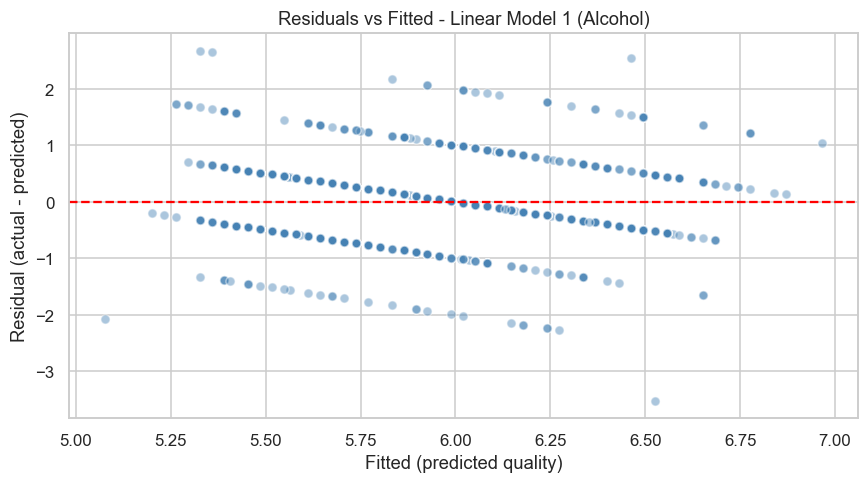

In [36]:
# Residuals = true value - predicted value on the test set for Linear Model 1
residuals = y_test.values - y_pred_lr1

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(y_pred_lr1, residuals, alpha=0.45, color='steelblue', edgecolor='white')
ax.axhline(0, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Fitted (predicted quality)')
ax.set_ylabel('Residual (actual - predicted)')
ax.set_title('Residuals vs Fitted - Linear Model 1 (Alcohol)')
plt.tight_layout()
plt.show()

**What this shows:** Residuals are scattered roughly symmetrically around the dashed 0  with no obvious shape (RMSE = 0.7566 on the test set, MAE = 0.6027).

**Library:** Matplotlib is the right choice here because residual diagnostics are static, no need for interactivity

### 2c. Actual vs Predicted - both linear models (Matplotlib)

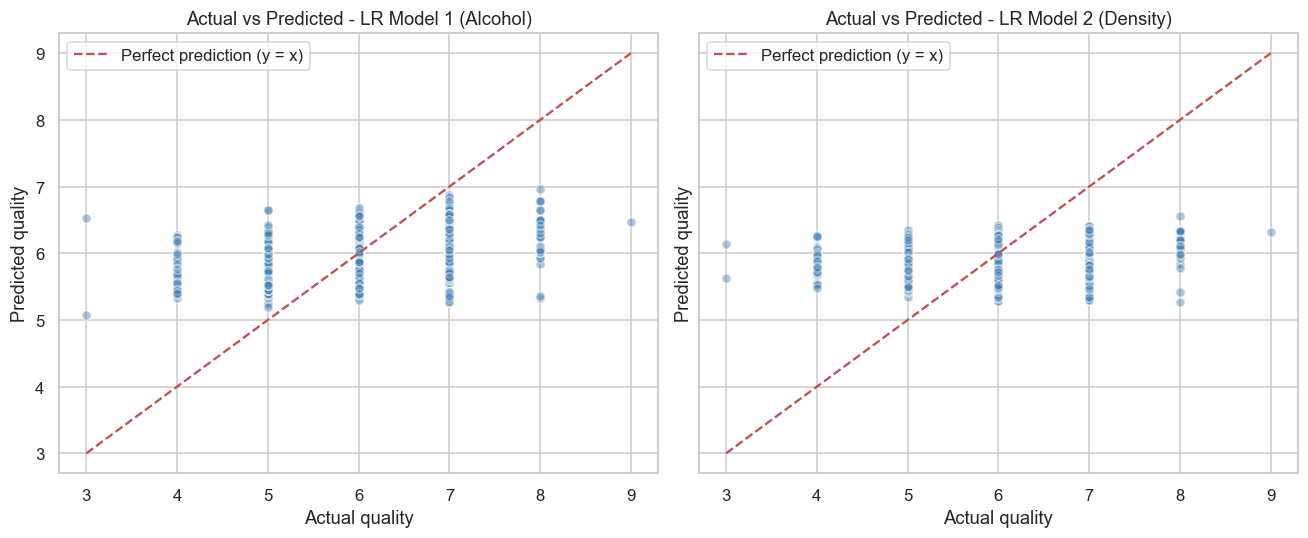

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, yhat, name in [
    (axes[0], y_pred_lr1, 'LR Model 1 (Alcohol)'),
    (axes[1], y_pred_lr2, 'LR Model 2 (Density)'),
]:
    ax.scatter(y_test, yhat, alpha=0.45, color='steelblue', edgecolor='white')
    lims = [min(y_test.min(), yhat.min()), max(y_test.max(), yhat.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction (y = x)')
    ax.set_xlabel('Actual quality')
    ax.set_ylabel('Predicted quality')
    ax.set_title(f'Actual vs Predicted - {name}')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**What this shows:** Each subplot puts actual quality on the x-axis and predicted on the y-axis with a red 45 degree prediction reference line. Model 1 (alcohol, R square = 0.2024) produces a tighter gathering around the diagonal than Model 2 (density, R square = 0.1144), confirming that alcohol is the stronger single predictor.

**Library choice:** The tighter the scatter to the diagonal, the better the model. This visualises the R square difference reported in 2a in a way that does not require numberid representation. Matplotlib's subplot grid plus `sharey=True` makes the side by side comparison honest and the static output is appropriate for a written report.

## Multiple

### 3a. Feature importance from Multiple Regression Model 1 (Matplotlib)

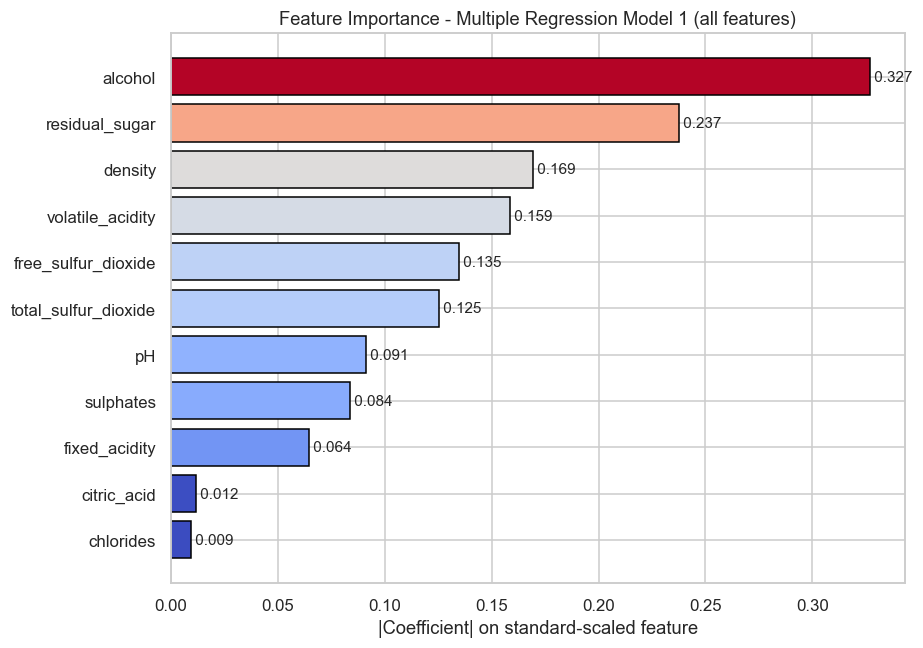

In [37]:
# lr_multi1 used standard-scaled features, so I can compare coefficient sizes
coefs = pd.Series(lr_multi1.coef_, index=X_train.columns).abs().sort_values()
norm = (coefs - coefs.min()) / (coefs.max() - coefs.min() + 1e-9)
colors = plt.cm.coolwarm(norm.values)

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(coefs.index, coefs.values, color=colors, edgecolor='black')
ax.set_xlabel('|Coefficient| on standard-scaled feature')
ax.set_title('Feature Importance - Multiple Regression Model 1 (all features)')
for idx, val in enumerate(coefs.values):
    ax.text(val, idx, f' {val:.3f}', va='center')
plt.tight_layout()
plt.show()

**What this shows:** The horizontal bar chart ranks every wine feature by the absolute size of its scaled regression coefficient. The top five contributors in absolute scaled coefficient are `alcohol`, `residual_sugar`, `density`, `volatile_acidity` and `free_sulfur_dioxide`. Multiple Regression Model 2 in CA1 retains `alcohol`, `volatile_acidity` and `density` (top 3) dropping `residual_sugar` because it correlates strongly with `density` and has a near 0 raw correlation with `quality` (-0.023 from Section 1a).

**Library:** Matplotlib was chosen here because `barh` plus a normalised `coolwarm` colour mapping gives a well styled ranked bar chart with text labels in a few lines. The chart confirms that R square drops only from 0.2751 (Model 1) to 0.2439 (Model 2).

### 3b. Actual vs Predicted - Model 1 vs Model 2 (Plotly showcase)

In [38]:
# Put both model predictions in one simple DataFrame for px.scatter
plot_df = pd.concat([
    pd.DataFrame({'actual': y_test.values, 'predicted': y_pred_multi1,
                  'model': 'Model 1 (all 11 features)'}),
    pd.DataFrame({'actual': y_test.values, 'predicted': y_pred_multi2,
                  'model': 'Model 2 (alcohol/vol_acid/density)'}),
])

lo = float(plot_df[['actual', 'predicted']].min().min())
hi = float(plot_df[['actual', 'predicted']].max().max())

fig = px.scatter(plot_df, x='actual', y='predicted', color='model',
                 opacity=0.55,
                 title='Multiple Regression - Actual vs Predicted (Model 1 vs Model 2)',
                 labels={'actual': 'Actual quality', 'predicted': 'Predicted quality'})
fig.add_shape(type='line', x0=lo, y0=lo, x1=hi, y1=hi,
              line=dict(color='red', dash='dash'))
fig.update_layout(width=820, height=520, legend_title_text='')
fig.show()

print(f'Model 1 R² = {r2_score(y_test, y_pred_multi1):.4f}')
print(f'Model 2 R² = {r2_score(y_test, y_pred_multi2):.4f}')

Model 1 R² = 0.2751
Model 2 R² = 0.2439


Both model traces are close to the red 45 degree line, with Model 1 ( 0.2751) tighter than Model 2 (0.2439) Because the chart is interactive, users can compare the spread of each model in isolation by clicking on the entries.

**Library** Plotly produces this comparison chart in fewer lines than Matplotlib for multi trace overlays. the colour split is automatic from a single tidy DataFrame and the built-in hover tooltip requires no extra setup. The `add_shape` call draws the diagonal reference line at the actual `(lo, hi)` range of the predictions in one statement, and the legend toggle is interactivity that a static Matplotlib chart cannot provide.

### 3c. Coefficient comparison with statsmodels error bars (Seaborn)

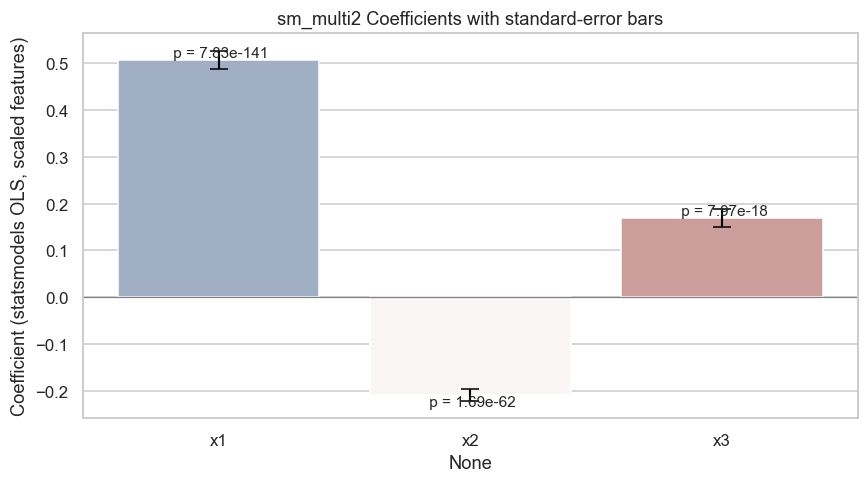

Coefficients, std errors and p-values:
      coef  std_err  p_value
x1  0.5077   0.0193      0.0
x2 -0.2092   0.0123      0.0
x3  0.1697   0.0196      0.0


In [39]:
# sm_multi2 is a statsmodels OLS model with 3 scaled features. 
# bse means standard errors.
params = sm_multi2.params.drop('const', errors='ignore')
errs = sm_multi2.bse.loc[params.index]
pvals = sm_multi2.pvalues.loc[params.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
# hue=index and legend=False stop seaborn 0.13+ warnings when I use a palette.
# errorbar=None turns off seaborn CI bars. I add my own statsmodels SE bars below.
# These manual bars are the only error bars on the chart.
sns.barplot(x=params.index, y=params.values, ax=ax,
            hue=params.index, palette='vlag', legend=False, errorbar=None)
ax.errorbar(range(len(params)), params.values, yerr=errs.values,
            fmt='none', color='black', capsize=6, linewidth=1.4)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Coefficient (statsmodels OLS, scaled features)')
ax.set_title('sm_multi2 Coefficients with standard-error bars')
for i, (val, p) in enumerate(zip(params.values, pvals.values)):
    ax.text(i, val, f' p = {p:.3g}', ha='center',
            va='bottom' if val >= 0 else 'top', fontsize=10)
plt.tight_layout()
plt.show()

print('Coefficients, std errors and p-values:')
print(pd.DataFrame({'coef': params, 'std_err': errs, 'p_value': pvals}).round(4))

All 3 selected features have coefficients several standard errors away from zero(the black error bars). The fitted scaled coefficients are `alcohol` = +0.508 (std err 0.019), `volatile_acidity` = -0.209 (std err 0.012), `density` = +0.170 (std err 0.020), and the annotated p-values are zero (< 0.001) for all 3.This is (CA1 OLS summary (Adj R² = 0.245, F = 441.3, all t-stats |t| > 8))

**Library:** Seaborn's `barplot` is paired here with Matplotlib's `errorbar` so the same axes carry both the magnitude (bar height) and the uncertainty (whisker length). 1 chart instead of two tables. `errorbar=None` prevents seaborn from also drawing its own bootstrap CI on top of the manual statsmodels SE bars.

## Polynomial

### 4a. Polynomial degree comparison (Matplotlib)

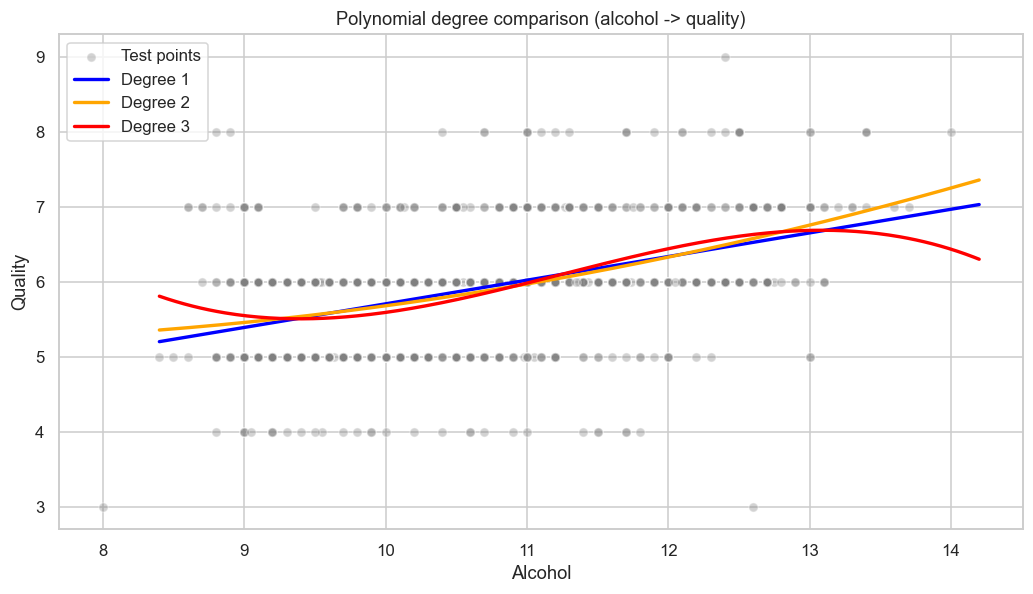

In [40]:
# Fit new PolynomialFeatures(1, 2, 3) on alcohol training data 
alc_train = X_train['alcohol'].values.reshape(-1, 1)
alc_test = X_test_lr['alcohol'].values
y_test_arr = y_test.values

grid = np.linspace(alc_train.min(), alc_train.max(), 300).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.scatter(alc_test, y_test_arr, alpha=0.35, color='gray', edgecolor='white',
           label='Test points')
for d, color in zip([1, 2, 3], ['blue', 'orange', 'red']):
    pf = PolynomialFeatures(degree=d, include_bias=False)
    X_tr = pf.fit_transform(alc_train)
    model = LinearRegression().fit(X_tr, y_train)
    grid_t = pf.transform(grid)
    ax.plot(grid.flatten(), model.predict(grid_t),
            color=color, linewidth=2.2, label=f'Degree {d}')

ax.set_xlabel('Alcohol')
ax.set_ylabel('Quality')
ax.set_title('Polynomial degree comparison (alcohol -> quality)')
ax.legend()
plt.tight_layout()
plt.show()

The blue (degree 1, test r square = 0.2024) and orange (degree 2, test r square = 0.2047) curves are difficult to differ across the bulk of the alcohol range. degree 2 has only +0.0023  r square. The red (degree 3) curve starts to bend at the extremes where there are fewer training points (a  sign of overfitting at the tails).

**Library** Matplotlib was chosen here because overlaying three polynomial curves on the same set of axes plus a faint scatter of test points is a one loop pattern in pyplot. Bokeh would require a separate ColumnDataSource per curve. 

### 4b. Best-fit degree-2 curve with hover (Bokeh)

In [14]:
# Refit a clean degree-2 alcohol model, so predict() works simply for the plot
pf2 = PolynomialFeatures(degree=2, include_bias=False)
X_tr2 = pf2.fit_transform(X_train['alcohol'].values.reshape(-1, 1))
m2 = LinearRegression().fit(X_tr2, y_train)

grid_b = np.linspace(X_train['alcohol'].min(), X_train['alcohol'].max(), 250)
y_curve = m2.predict(pf2.transform(grid_b.reshape(-1, 1)))

src_pts = ColumnDataSource(data=dict(
    alcohol=X_test_lr['alcohol'].values, quality=y_test.values))
src_curve = ColumnDataSource(data=dict(alcohol=grid_b, predicted=y_curve))

p = figure(width=760, height=420,
           title='Polynomial degree-2 fit (alcohol -> quality)',
           x_axis_label='Alcohol', y_axis_label='Quality')
p.scatter('alcohol', 'quality', source=src_pts, color='steelblue',
          alpha=0.4, size=7, legend_label='Test points')
line = p.line('alcohol', 'predicted', source=src_curve, color='darkorange',
              line_width=3, legend_label='Degree-2 fit')

p.add_tools(HoverTool(renderers=[line], tooltips=[
    ('Alcohol', '@alcohol{0.00}'),
    ('Predicted quality', '@predicted{0.00}')
]))
p.legend.location = 'top_left'

display(HTML(file_html(p, CDN, 'Polynomial degree-2 alcohol -> quality')))

 The same degree-2 curve from 4a ( 0.2047) but interactive. Hovering moves a tooltip along the orange line revealing the predicted quality at any alcohol value across the 8.0-13.0 % training range, while the underlying scatter shows the actual test points the model is being judged on.

**Library** Switching to Bokeh here lets the user hover and invisigate individual predictions along the curve.  The `HoverTool(renderers=[line], ...)` pattern restricts the tooltip to the curve only

### 4c. Residuals - Poly Model 1 vs Poly Model 2 (Matplotlib 1x2)

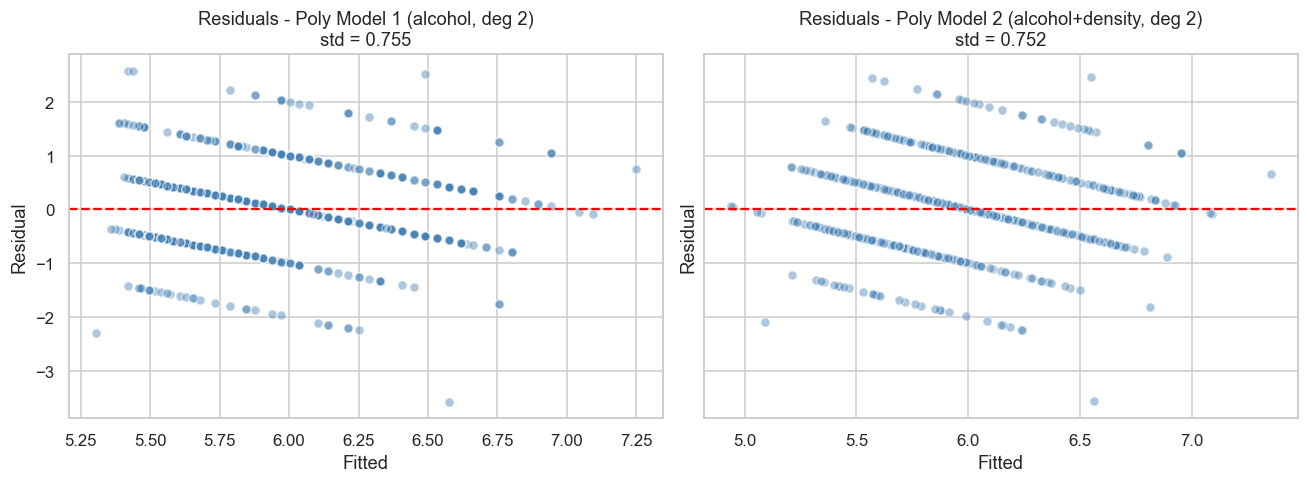

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, yhat, name in [
    (axes[0], y_pred_poly1, 'Poly Model 1 (alcohol, deg 2)'),
    (axes[1], y_pred_poly2, 'Poly Model 2 (alcohol+density, deg 2)'),
]:
    res = y_test.values - yhat
    ax.scatter(yhat, res, alpha=0.45, color='steelblue', edgecolor='white')
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Fitted')
    ax.set_ylabel('Residual')
    ax.set_title(f'Residuals - {name}\nstd = {np.std(res):.3f}')
plt.tight_layout()
plt.show()

Both residual clouds sit symmetrically around zero. The standard deviation reported in each subtitle is slightly lower for Poly Model 2 (alcohol + density, deg 2) than Poly Model 1 (alcohol only, deg 2.

**Library** Matplotlib's 1x2 subplot layout with `sharey=True` puts the two clouds at the same vertical scale so the spread comparison is honest.

## Logistic

### 5a. Logistic sigmoid - Model 1 sliced on alcohol (Matplotlib)

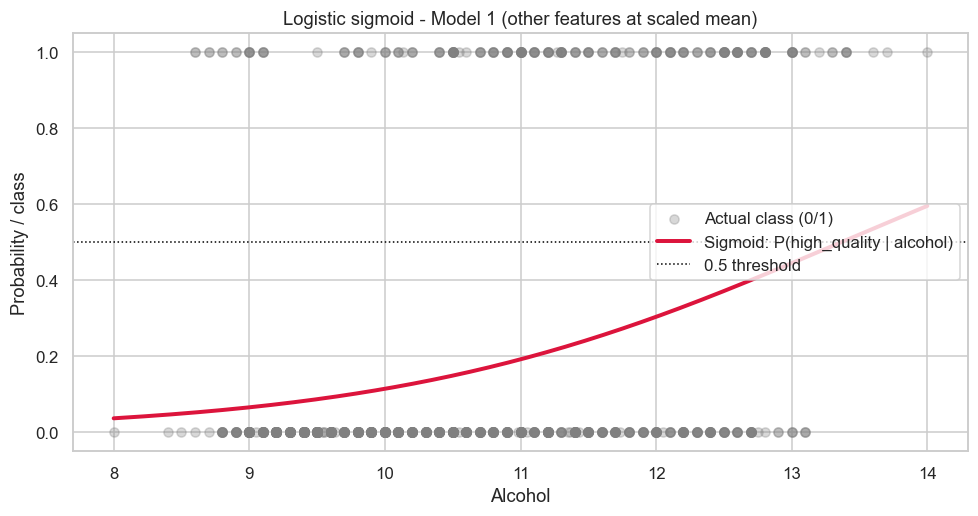

In [41]:
feature_names = list(X_train.columns)
i_alc = feature_names.index('alcohol')
mean_alc = scaler_cls.mean_[i_alc]
scale_alc = scaler_cls.scale_[i_alc]

raw_grid = np.linspace(X_test_cls['alcohol'].min(), X_test_cls['alcohol'].max(), 300)
z_alc = (raw_grid - mean_alc) / scale_alc
intercept = log_model1.intercept_[0]
coef_alc = log_model1.coef_[0][i_alc]
z = intercept + coef_alc * z_alc
prob = 1.0 / (1.0 + np.exp(-z))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(X_test_cls['alcohol'].values, y_test_cls.values, alpha=0.3,
           color='gray', label='Actual class (0/1)')
ax.plot(raw_grid, prob, color='crimson', linewidth=2.6,
        label='Sigmoid: P(high_quality | alcohol)')
ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='0.5 threshold')
ax.set_xlabel('Alcohol')
ax.set_ylabel('Probability / class')
ax.set_title('Logistic sigmoid - Model 1 (other features at scaled mean)')
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

**What this shows:** The grey 0/1 dots are the actual class labels plotted along the alcohol axis. The crimson S-curve is the predicted probability of `high_quality = 1` from Logistic Model 1, computed by holding the other ten features at their training-set mean (so their scaled values are zero) and sweeping alcohol across the test range. The dotted line at 0.5 is the decision threshold; on this slice the curve crosses 0.5 at approximately 12 % alcohol, which is the implied alcohol decision boundary for an 'average' wine. Test accuracy of Model 1 is 0.8135.

**Library rationale:** Matplotlib is the natural fit here because the curve is smooth and static, and combining the scatter, the analytic sigmoid line and a horizontal threshold line is straightforward with three function calls. Working in scaled space and converting only the alcohol axis back to raw units keeps the maths transparent and avoids any hidden inverse-transform.

### 5b. Confusion matrix heatmaps (Seaborn 1x2)

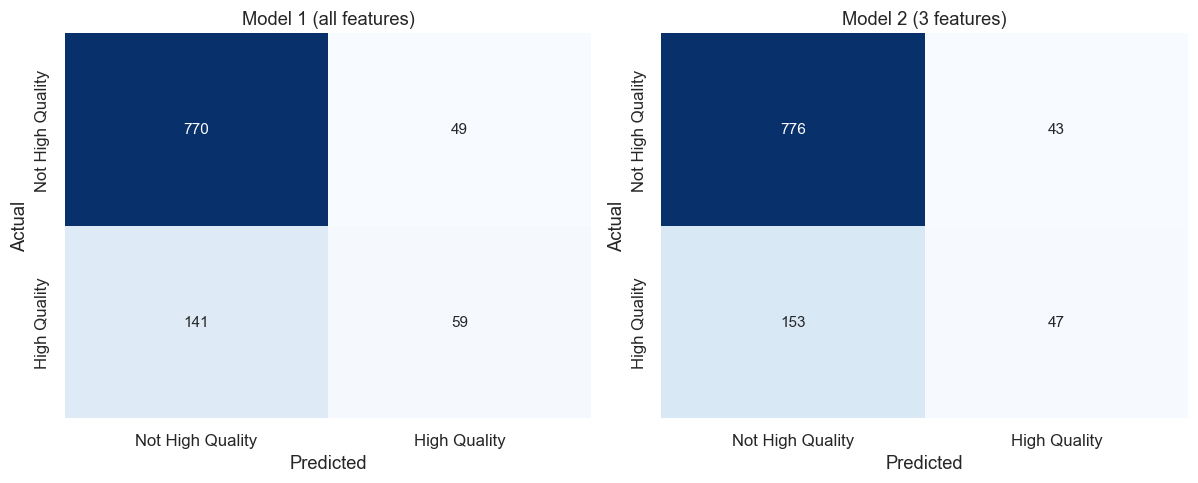

In [17]:
# Make confusion matrices again with sklearn, so the shape is always the same
# Link: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
cm1 = confusion_matrix(y_test_cls, y_pred_log1)
cm2 = confusion_matrix(y_test_cls, y_pred_log2)
labels = ['Not High Quality', 'High Quality']

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, cm, name in [
    (axes[0], cm1, 'Model 1 (all features)'),
    (axes[1], cm2, 'Model 2 (3 features)'),
]:
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**What this shows:** Both models classify most majority-class wines correctly (top-left cell - 770 / 819 correct for Model 1, 778 / 819 for Model 2 - 94-95 % recall on class 0). Model 1 (all features) catches 58 / 200 true high-quality wines (recall 0.29) while Model 2 (3 features) catches 46 / 200 (recall 0.23) - so dropping eight features costs ~12 minority-class true positives while only adding 8 correct majority-class calls. Overall accuracy is 0.8135 vs 0.8077 (a 0.6 pp drop).

**Library rationale:** Seaborn's annotated heatmap is the cleanest way to communicate a confusion matrix because the shaded background draws the eye to the diagonal where correct predictions live. This visualisation directly backs up the precision/recall numbers in the CA1 classification reports and quantifies the cost of the smaller-feature model in human terms (true high-quality wines missed).

### 5c. ROC curves - both logistic models (Matplotlib)

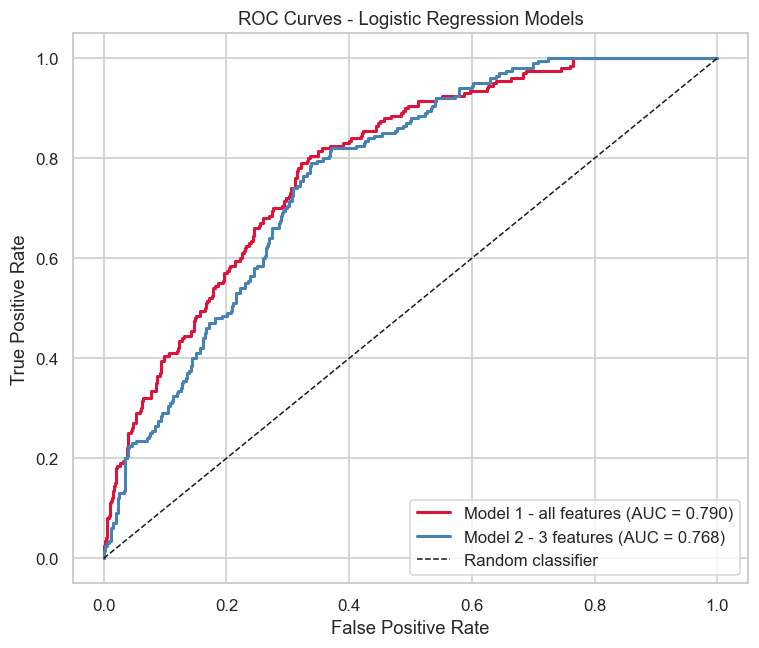

Logistic Model 1 AUC = 0.7903
Logistic Model 2 AUC = 0.7681


In [18]:
# Positive class probabilities from each model on its own test data
# Link: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html
proba1 = log_model1.predict_proba(X_test_cls_scaled)[:, 1]
proba2 = log_model2.predict_proba(X_test_cls2_scaled)[:, 1]

fpr1, tpr1, _ = roc_curve(y_test_cls, proba1)
fpr2, tpr2, _ = roc_curve(y_test_cls, proba2)
auc1 = auc(fpr1, tpr1)
auc2 = auc(fpr2, tpr2)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr1, tpr1, color='crimson', linewidth=2,
        label=f'Model 1 - all features (AUC = {auc1:.3f})')
ax.plot(fpr2, tpr2, color='steelblue', linewidth=2,
        label=f'Model 2 - 3 features (AUC = {auc2:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves - Logistic Regression Models')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'Logistic Model 1 AUC = {auc1:.4f}')
print(f'Logistic Model 2 AUC = {auc2:.4f}')

**What this shows:** Both ROC curves bow well above the dashed diagonal (random baseline). Model 1 (all 11 features) reaches AUC = 0.7903 and Model 2 (alcohol + volatile_acidity + density) reaches AUC = 0.7681 - the printed values under the chart confirm these. The 0.022 AUC gap means Model 1 has a marginally better ranking of positive vs negative wines across all thresholds.

**Library rationale:** Both AUCs are clearly above 0.5 (random) but below 0.8, which is consistent with the modest accuracy/recall numbers in 5b - the wine-quality signal is real but weak. Matplotlib was chosen here because two ROC curves plus a baseline line are three function calls; Plotly would add only a hover tooltip that does not aid the qualitative shape comparison.

### 5d. Logistic Model 2 coefficients (Plotly)

In [19]:
# log_model2.coef_[0] has 3 values in the same order as selected_cls
# Link: https://plotly.com/python/bar-charts/
coefs_log2 = log_model2.coef_[0]
coef_df = pd.DataFrame({
    'feature': selected_cls,
    'coefficient': coefs_log2,
    'sign': np.where(coefs_log2 >= 0, 'positive', 'negative')
})

fig = px.bar(coef_df, x='feature', y='coefficient', color='sign',
             color_discrete_map={'positive': 'seagreen', 'negative': 'crimson'},
             title='Logistic Model 2 - feature coefficients (scaled)',
             text=coef_df['coefficient'].round(3))
fig.update_layout(width=700, height=450, legend_title_text='')
fig.update_traces(textposition='outside')
fig.show()

**What this shows:** `alcohol` has by far the strongest positive coefficient (+1.308 in scaled space - more alcohol means materially higher P(high_quality)). `volatile_acidity` has the strongest negative coefficient (-0.555 - more vinegar character means lower P(high_quality)). `density` is positive at +0.344 - a useful contrast with the linear-regression case where density's raw correlation with `quality` is negative (-0.311 in Section 1a): once alcohol and acidity are conditioned on, density's residual signal flips sign in the logistic model, which is a textbook multivariate effect.

**Library rationale:** Plotly's `px.bar` is used here instead of Matplotlib because the discrete colour mapping by sign (`color_discrete_map={'positive': 'seagreen', 'negative': 'crimson'}`) and the per-bar value labels (`text=...`, `textposition='outside'`) are configured with single arguments. Hover tooltips are also free out of the box.

## Time Series

### 6a. Seasonal decomposition (Matplotlib 4-panel)

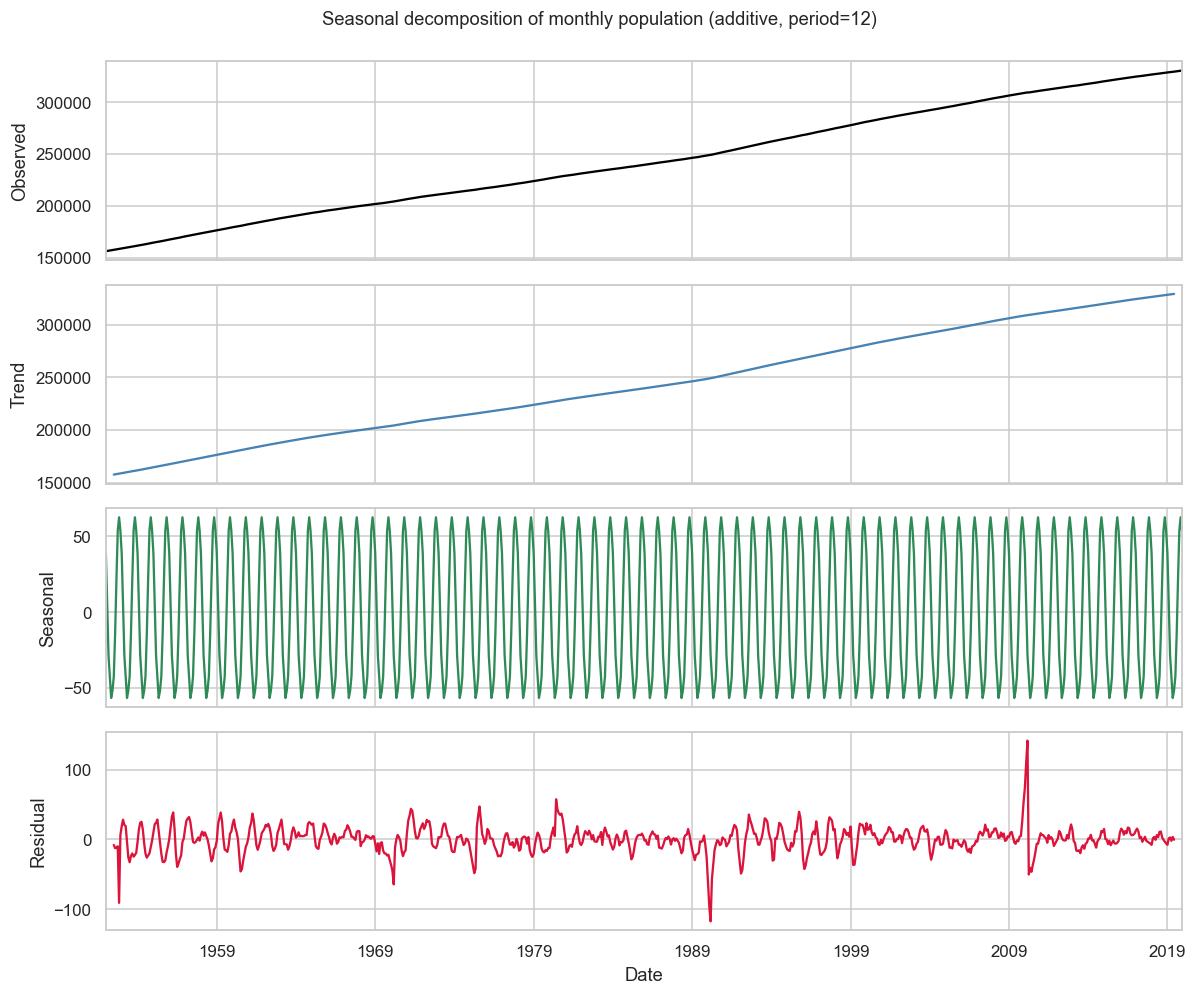

In [20]:
# decomp was made in CA2 with seasonal_decompose(y, model='additive', period=12)
# Link: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
decomp.observed.plot(ax=axes[0], color='black')
axes[0].set_ylabel('Observed')
decomp.trend.plot(ax=axes[1], color='steelblue')
axes[1].set_ylabel('Trend')
decomp.seasonal.plot(ax=axes[2], color='seagreen')
axes[2].set_ylabel('Seasonal')
decomp.resid.plot(ax=axes[3], color='crimson')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Date')
fig.suptitle('Seasonal decomposition of monthly population (additive, period=12)', y=1.0)
plt.tight_layout()
plt.show()

**What this shows:** Four panels: the observed monthly population grows almost monotonically from 156,309 (Jan 1952) to 330,310 (Dec 2019) - a +111 % increase over 68 years. The trend panel confirms a smooth upward path. The seasonal component oscillates between roughly -57 and +63 (mean absolute = 39.5, vs a level mean of 243,848 - a small but visually clear ~0.02 % cycle). Residuals hover around zero with limited structure.

**Library rationale:** The combination of a strong, near-deterministic trend (Section 1c CA2 ADF p = 0.86, non-stationary in level) and a clear 12-month seasonal cycle is exactly what motivates SARIMAX in CA2 - SARIMAX has explicit machinery for the seasonal component while ARIMA absorbs it inefficiently. Matplotlib's 4-panel `sharex=True` layout puts trend, seasonal and residual on the same time axis so the eye can correlate features at the same dates.

### 6b. Interactive time series with hvplot

In [26]:
# Two interactive time charts with hvplot: monthly population and 12-month rolling mean
import re

pop_plot_df = pd.concat([
    y.rename('Monthly population'),
    y.rolling(12).mean().rename('12m MA'),
], axis=1)

ts_chart = pop_plot_df.hvplot(
    subplots=True, shared_axes=False,
    title='Monthly Population (full series)',
    ylabel='Population', xlabel='Date',
    width=750, height=220,
).cols(1)

# Show Bokeh as saved HTML instead of using HoloViews notebook display.
# The notebook display can fail to show again in VSCode after a restart.
ts_model = hv.render(ts_chart, backend='bokeh')
html_ts = file_html(ts_model, CDN, 'Monthly Population hvplot subplots')
html_ts = re.sub(r'<script[^>]*src="static/[^"]*"[^>]*></script>\s*', '', html_ts)
display(HTML(html_ts))

**What this shows:** The blue line is the raw 816-month population series (1952-01 to 2019-12, ranging 156,309 to 330,310) and the orange overlay is the 12-month rolling mean, smoothing out the seasonal cycle of ±60 visible in 6a. The chart supports pan and zoom out of the box, so the reader can isolate any decade by dragging or scrolling.

**Library rationale:** hvplot is used here because passing `subplots=True` to a two-column DataFrame splits the raw Series and the 12-month rolling mean into stacked Bokeh-backed panels in a single method call, with `.cols(1)` controlling the layout - giving each series its own y-axis so the smoothing and the seasonality are easier to read side by side. Matplotlib would produce a static equivalent in several lines with manual axis formatting; raw Bokeh would require building two ColumnDataSources before getting equivalent interactivity.

### 6c. Train/test + three model forecasts (Matplotlib)

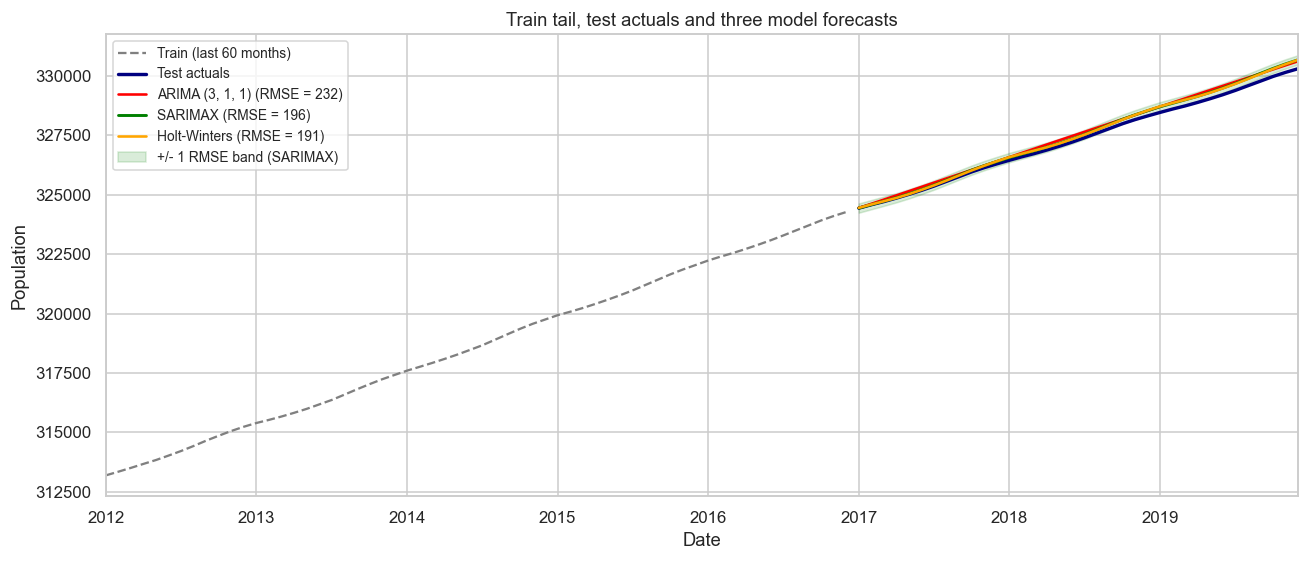

In [22]:
# Get each model RMSE from the CA2 metrics table for the legend
mt = metrics_test.set_index('model')
arima_label = next(c for c in mt.index if str(c).startswith('ARIMA'))
sar_label = next(c for c in mt.index if str(c).startswith('SARIMAX'))
hw_label = next(c for c in mt.index if 'Holt' in str(c))
rmse_arima = mt.loc[arima_label, 'RMSE']
rmse_sar = mt.loc[sar_label, 'RMSE']
rmse_hw = mt.loc[hw_label, 'RMSE']

fig, ax = plt.subplots(figsize=(12, 5.2))
train.iloc[-60:].plot(ax=ax, color='gray', linestyle='--', label='Train (last 60 months)')
test.plot(ax=ax, color='navy', linewidth=2.2, label='Test actuals')
fc_arima.plot(ax=ax, color='red', linewidth=1.7,
              label=f'ARIMA {arima_order} (RMSE = {rmse_arima:,.0f})')
fc_sar.plot(ax=ax, color='green', linewidth=1.9,
            label=f'SARIMAX (RMSE = {rmse_sar:,.0f})')
fc_hw.plot(ax=ax, color='orange', linewidth=1.7,
           label=f'Holt-Winters (RMSE = {rmse_hw:,.0f})')

ax.fill_between(fc_sar.index, fc_sar - rmse_sar, fc_sar + rmse_sar,
                color='green', alpha=0.15, label='+/- 1 RMSE band (SARIMAX)')
ax.set_ylabel('Population')
ax.set_xlabel('Date')
ax.set_title('Train tail, test actuals and three model forecasts')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

**What this shows:** All three forecasts track the dark-blue test actuals reasonably over the 36-month test horizon (2017-01 to 2019-12). The legend reports their test RMSE: ARIMA(3,1,1) = 232, SARIMAX(1,1,1)(0,1,1,12) = 196 and Holt-Winters_add_m12 = 191. Holt-Winters and SARIMAX are within 5 units RMSE of each other, while plain ARIMA drifts noticeably above the actual trajectory because it cannot model the 12-month seasonal cycle. The green shaded ±1 RMSE band around the SARIMAX forecast envelopes nearly all of the navy actuals, demonstrating that the SARIMAX point forecast is well-calibrated.

**Library rationale:** Holt-Winters is technically the best test-set performer on every error metric (Section 6f), but SARIMAX is the model CA2 selects for the long-horizon projection (`final_sar` in 6e) because it has explicit, interpretable structural components (seasonal AR/MA terms) and its test RMSE is statistically indistinguishable from Holt-Winters'. Matplotlib was chosen here because `fill_between` plus three line plots is a single-figure pattern that no interactive library matches in code economy; the static output is also easier to embed in the report.

### 6d. Interactive Bokeh forecast with RangeSlider widget

In [27]:
# Build data for train data, test data, and SARIMAX forecast. Link widgets to the chart.
# Link: https://docs.bokeh.org/en/latest/docs/user_guide/interaction/widgets.html#rangeslider
train_tail = train.iloc[-60:]

# RangeSlider works only with numbers, so I make a number date_num column
# (unix milliseconds) alongside the original timestamp - Bokeh's datetime axis interprets ms.
def _ms(idx):
    return [int(pd.Timestamp(d).value // 1_000_000) for d in idx]

if isinstance(fc_future, pd.Series):
    future_forecast = fc_future.copy()
else:
    future_forecast = pd.Series(np.asarray(fc_future).ravel(), index=future_idx)

initial_horizon = min(12, len(future_forecast))

src_train = ColumnDataSource(data=dict(
    date_num=_ms(train_tail.index), date=list(train_tail.index),
    value=train_tail.values.tolist()))
src_test = ColumnDataSource(data=dict(
    date_num=_ms(test.index), date=list(test.index),
    value=test.values.tolist()))
src_sar = ColumnDataSource(data=dict(
    date_num=_ms(fc_sar.index), date=list(fc_sar.index),
    value=fc_sar.values.tolist()))
src_future_full = ColumnDataSource(data=dict(
    date_num=_ms(future_forecast.index), date=list(future_forecast.index),
    value=future_forecast.values.tolist()))
src_future = ColumnDataSource(data=dict(
    date_num=_ms(future_forecast.index[:initial_horizon]),
    date=list(future_forecast.index[:initial_horizon]),
    value=future_forecast.iloc[:initial_horizon].values.tolist()))

# Make a sorted list of dates and matching millisecond numbers
combined_idx = sorted(set(list(train_tail.index) + list(test.index) + list(future_forecast.index)))
date_nums = _ms(combined_idx)
n = len(combined_idx)

# Use Range1d so the CustomJS slider can change start and end
p = figure(x_axis_type='datetime', width=820, height=400,
           title='Population - SARIMAX forecast dashboard',
           x_axis_label='Date', y_axis_label='Population',
           x_range=Range1d(start=date_nums[0], end=date_nums[-1]))
p.line('date_num', 'value', source=src_train, color='gray',
       line_dash='dashed', line_width=2, legend_label='Train tail (60m)')
p.line('date_num', 'value', source=src_test, color='navy',
       line_width=2.2, legend_label='Test actuals')
p.line('date_num', 'value', source=src_sar, color='green',
       line_width=2.5, legend_label='SARIMAX test forecast')
p.line('date_num', 'value', source=src_future, color='purple',
       line_width=2.5, line_dash='dotdash', legend_label='Future forecast horizon')
p.add_tools(HoverTool(
    tooltips=[('Date', '@date{%F}'), ('Value', '@value{0,0}')],
    formatters={'@date': 'datetime'}))
p.legend.location = 'top_left'
p.legend.click_policy = 'hide'

slider = RangeSlider(start=0, end=n - 1, value=(0, n - 1), step=1,
                     title='Zoom date range (index)')
slider_callback = CustomJS(args=dict(x_range=p.x_range, ms=date_nums), code="""
    const v = cb_obj.value;
    x_range.start = ms[Math.floor(v[0])];
    x_range.end = ms[Math.floor(v[1])];
""")
slider.js_on_change('value', slider_callback)

horizon_spinner = Spinner(title='Forecast horizon (months)', low=1,
                          high=len(future_forecast), step=1,
                          value=initial_horizon, width=220)
horizon_callback = CustomJS(args=dict(source=src_future, full_source=src_future_full), code="""
    const n = Math.floor(cb_obj.value);
    const next_data = {};
    for (const key in full_source.data) {
        next_data[key] = full_source.data[key].slice(0, n);
    }
    source.data = next_data;
    source.change.emit();
""")
horizon_spinner.js_on_change('value', horizon_callback)

import re

lay = layout([[slider, horizon_spinner], [p]])
html_widget = file_html(lay, CDN, 'Population Dashboard')
# hv.extension('bokeh') adds Panel as a Bokeh extension.
# This adds a local es-module-shims script to file_html. It gives a 404 outside Jupyter.
# That stops the widget JavaScript, so remove it for offline opening.
html_widget = re.sub(r'<script[^>]*src="static/[^"]*"[^>]*></script>\s*', '', html_widget)
display(HTML(html_widget))

In [29]:
with open("forecast_widget.html", "w", encoding="utf-8") as f:
    f.write(html_widget)

**What this shows:** The same SARIMAX forecast as 6c (RMSE = 196 over the 36-month test horizon), plus the forward projection from CA2. The dual-handle `RangeSlider` lets the reader collapse the x-range to any sub-window of the plotted history/test/future period, while the `Spinner` adjusts how many future forecast months are shown. Hovering reveals the exact date and population value for every point on every line.

**Library rationale:** Bokeh's widget framework was chosen here because the `RangeSlider` plus a `CustomJS` callback updating an explicit `Range1d` gives custom range zoom on a datetime axis, and the `Spinner` uses a second `CustomJS` callback to change the forecast horizon without round-tripping to the Python kernel. The `'date_num'` (numeric milliseconds) column is used in the ColumnDataSource because Bokeh's RangeSlider only operates on numeric values. hvplot (Section 6b) provides interactivity with less code but offers no custom widget controls; Matplotlib (Section 6c) is better for static publication output.

### 6e. Future 24-month projection (Plotly)

In [ ]:
# History (last 60 months) and the 24-month SARIMAX forecast from CA2
hist = y.iloc[-60:]
if isinstance(fc_future, pd.Series):
    proj = fc_future.copy()
else:
    proj = pd.Series(np.asarray(fc_future).ravel(), index=future_idx)
proj.name = 'value'

hist_df = hist.reset_index()
hist_df.columns = ['date', 'value']
hist_df['series'] = 'History (last 60m)'
proj_df = proj.reset_index()
proj_df.columns = ['date', 'value']
proj_df['series'] = 'Forecast (next 24m)'
plot_df = pd.concat([hist_df, proj_df], ignore_index=True)

fig = px.line(plot_df, x='date', y='value', color='series',
              title='Population - last 5 years + 24-month SARIMAX projection',
              labels={'date': 'Date', 'value': 'Population'})

# add_vline accepts an ISO date string ("YYYY-MM-DD") on a datetime x-axis.
# I add the text with add_annotation, so Plotly does not place it inside add_vline.
# Plotly 5.x can fail when the line and text are sent in one add_vline call.
boundary_str = pd.Timestamp(hist.index[-1]).strftime('%Y-%m-%d')
fig.add_vline(x=boundary_str, line_dash='dash', line_color='gray')
fig.add_annotation(x=boundary_str, y=1, xref='x', yref='paper',
                   text='Forecast start', showarrow=False,
                   yanchor='bottom', font=dict(color='gray'))
fig.update_layout(width=860, height=460, legend_title_text='')
fig.show()

**What it shows:** The blue history segment shows the last 60 months of population. The dashed vertical line marks the forecast boundary. The upward trend continues with the same 12-month seasonal cycle visible in 6a.

**Library rationale:** Plotly was chosen here because `add_vline` adds the forecast boundary cleanly in one call when given an ISO-formatted timestamp string. The hover tooltip automatically shows formatted dates and population values, and the legend toggle lets the reader hide the history segment to inspect just the forward projection in isolation - none of which require extra setup.

### 6f. Model comparison metrics (Seaborn)

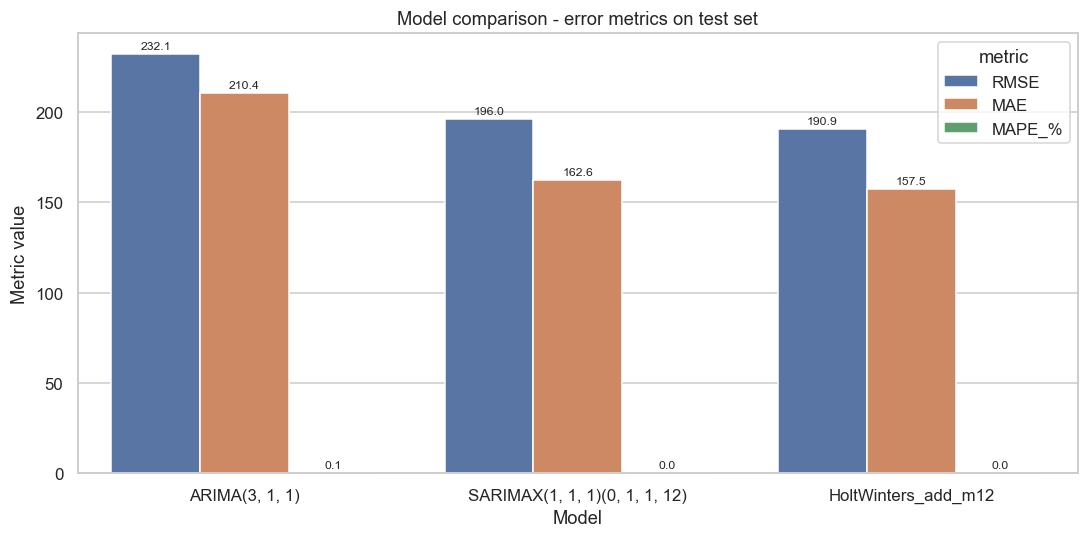

                           model        RMSE         MAE    MAPE_%
0                 ARIMA(3, 1, 1)  232.125195  210.401044  0.064133
1  SARIMAX(1, 1, 1)(0, 1, 1, 12)  195.958753  162.596714  0.049496
2            HoltWinters_add_m12  190.858521  157.496115  0.047942


In [ ]:
# Long metrics table: one row for each model and metric
m_long = metrics_test.melt(id_vars='model', var_name='metric', value_name='value')

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=m_long, x='model', y='value', hue='metric', ax=ax)
ax.set_title('Model comparison - error metrics on test set')
ax.set_ylabel('Metric value')
ax.set_xlabel('Model')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()

print(metrics_test)

**What this shows:** Three groups, one per model, with the three error metrics (RMSE, MAE, MAPE_%) shown side by side. Holt-Winters has the lowest bars on all three metrics, SARIMAX is a close second, and ARIMA is worse on every metric.

**Library rationale:** Holt-Winters wins the test set error contest. Seaborn's grouped `barplot` with `hue` is exactly the right tool for comparison models and their metrics from a melted DataFrame, and `ax.bar_label` adds the numeric labels in one loop.

## References

- Bokeh - https://docs.bokeh.org
- hvplot - https://hvplot.holoviz.org
- Plotly Python - https://plotly.com/python/
- Seaborn - https://seaborn.pydata.org
- Matplotlib - https://matplotlib.org/stable/
- scikit-learn - https://scikit-learn.org/stable/
- statsmodels - https://www.statsmodels.org
- UCI Wine Quality dataset (id=186) - https://archive.ics.uci.edu/dataset/186/wine+quality